In [6]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt
from EDA_Funcions.eda_utils import gerar_resumo_colunas
from EDA_Funcions.eda_utils import calcular_potencia_ativa_total, COLS_POTENCIA
from EDA_Funcions.eda_utils import calcular_estatisticas_globais, COLS_POTENCIA
from EDA_Funcions.eda_utils import calcular_potencia_ativa_total
from EDA_Funcions.eda_graficos import preparar_dados_temporais, plotar_calendario_mensal, plotar_dias_sequenciais
from EDA_Funcions.eda_utils import calcular_potencia_ativa_total
from EDA_Funcions.eda_graficos import preparar_dados_temporais, plotar_calendario_mensal, plotar_dias_sequenciais
from EDA_Funcions.eda_graficos import preparar_dados_temporais, plotar_calendario_mensal
from EDA_Funcions.eda_utils import calcular_potencia_ativa_total


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [7]:
caminho_ccet = "/home/ls/TCC_2026/Dados greefra/mes_1/dados_limpos/Medidor_CCET.csv"
caminho_bio = "/home/ls/TCC_2026/Dados greefra/mes_1/dados_limpos/Medidor_BIO.csv"
caminho_cch = "/home/ls/TCC_2026/Dados greefra/mes_1/dados_limpos/Medidor_CCH.csv"
caminho_ccso = "/home/ls/TCC_2026/Dados greefra/mes_1/dados_limpos/Medidor_CCSO.csv"
caminho_iee = "/home/ls/TCC_2026/Dados greefra/mes_1/dados_limpos/Medidor_IEE.csv"
caminho_odonto = "/home/ls/TCC_2026/Dados greefra/mes_1/dados_limpos/Medidor_ODONTO.csv"
caminho_pf = "/home/ls/TCC_2026/Dados greefra/mes_1/dados_limpos/Medidor_PF.csv"

In [8]:
caminho = [caminho_ccet, caminho_bio, caminho_cch, caminho_ccso, caminho_iee, caminho_odonto, caminho_pf]

In [18]:
# Carrega os dados (agora sem erros de Parser)
df_ccet = pd.read_csv(caminho_ccet)

/tmp/ipykernel_2351/3213781868.py:2: DtypeWarning: Columns (0: network.wifi_mode, 1: network.type, 2: network.ssid, 3: network.status, 4: network.rssi.unit, 5: network.signal.unit, 6: network.ipv4.type, 7: network.ipv4.address, 8: network.ipv4.subnet_mask, 9: network.ipv4.gateway, 10: network.ipv4.dns1, 11: network.ipv4.dns2, 12: network.ipv6.address, 13: lastgasp) have mixed types. Specify dtype option on import or set low_memory=False.
  df_ccet = pd.read_csv(caminho_ccet)


In [ ]:
# Exibe as primeiras 5 linhas para inspeção visual
display(df_ccet.head())

/tmp/ipykernel_2351/93589480.py:5: DtypeWarning: Columns (0: network.wifi_mode, 1: network.type, 2: network.ssid, 3: network.status, 4: network.rssi.unit, 5: network.signal.unit, 6: network.ipv4.type, 7: network.ipv4.address, 8: network.ipv4.subnet_mask, 9: network.ipv4.gateway, 10: network.ipv4.dns1, 11: network.ipv4.dns2, 12: network.ipv6.address, 13: lastgasp) have mixed types. Specify dtype option on import or set low_memory=False.
  df_ccet = pd.read_csv(caminho_ccet)


,id,server,item_name,sensor_type,location_description,timestamp_leitura_anterior,minutos_desde_ultima_leitura,flag_inatividade,horas_inativo,device.name,...,network.signal.value,network.signal.unit,network.ipv4.type,network.ipv4.address,network.ipv4.subnet_mask,network.ipv4.gateway,network.ipv4.dns1,network.ipv4.dns2,network.ipv6.address,lastgasp
0,341872,23299981,Medidor CCET,Energia,O medidor de energia está instalado na Subesta...,NaN,NaN,0,0.0,Telik Trafo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,341888,23299981,Medidor CCET,Energia,O medidor de energia está instalado na Subesta...,2025-08-01 00:00:02,5.0,0,0.0,Telik Trafo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,341906,23299981,Medidor CCET,Energia,O medidor de energia está instalado na Subesta...,2025-08-01 00:05:02,5.0,0,0.0,Telik Trafo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,341922,23299981,Medidor CCET,Energia,O medidor de energia está instalado na Subesta...,2025-08-01 00:10:02,5.0,0,0.0,Telik Trafo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,341939,23299981,Medidor CCET,Energia,O medidor de energia está instalado na Subesta...,2025-08-01 00:15:02,5.0,0,0.0,Telik Trafo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- Resumo Técnico do DataFrame ---


In [3]:
# Libera o limite visual do Pandas para exibir todas as linhas na tela
pd.set_option('display.max_rows', 150)

# Chama a nova função e exibe a tabela completa
tabela_resumo = gerar_resumo_colunas(df_ccet)
display(tabela_resumo)

,Tipo de Dado,Valores Preenchidos,Valores Faltantes (NaN)
id,int64,97357,0
server,int64,97357,0
item_name,str,97357,0
sensor_type,str,97357,0
location_description,str,97357,0
timestamp_leitura_anterior,str,97341,16
minutos_desde_ultima_leitura,float64,97341,16
flag_inatividade,int64,97357,0
horas_inativo,float64,97357,0
device.name,str,97357,0


In [4]:
# Calcula a demanda instantânea total do prédio
df_ccet = calcular_potencia_ativa_total(df_ccet)

# Usa a constante importada para exibir exatamente as colunas que importam
display(df_ccet[COLS_POTENCIA].head())

⚡ Coluna 'active_power.total' calculada e adicionada com sucesso!


,active_power.phase.a,active_power.phase.b,active_power.phase.c,active_power.total
0,17.127,8.904,11.981,38.012
1,13.799,8.141,12.197,34.137
2,17.229,11.415,12.723,41.367
3,16.111,8.932,12.181,37.224
4,15.662,9.263,11.793,36.718


In [5]:
# Chama a função passando a coluna que queremos investigar
estatisticas_potencia = calcular_estatisticas_globais(df_ccet, 'active_power.total')

# Exibe o resultado como uma tabela limpa
display(estatisticas_potencia)

📊 Estatísticas processadas para a coluna: 'active_power.total'


Mínimo (Min)          -65.326000
Máximo (Max)          352.326000
Média (Mean)           87.809089
Q1 (25%)               35.512000
Q2 / Mediana (50%)     43.801000
Q3 (75%)              122.940000
Percentil 95.0%       265.700400
Percentil 98.0%       295.817000
Percentil 99.0%       312.959000
Percentil 99.9%       337.981000
Name: Estatísticas Globais: active_power.total, dtype: float64

In [ ]:
# Importa as ferramentas e as DUAS funções de gráficos

# 1. Recalcula a Potência Total
df_ccet = calcular_potencia_ativa_total(df_ccet)

# 2. Trata os dados temporais e adiciona a coluna "dia_da_semana"
df_ccet = preparar_dados_temporais(df_ccet, coluna_tempo='timestamp_leitura_anterior')

# 3. Exibe algumas linhas para confirmar a nova coluna
display(df_ccet[['dia_da_semana', 'active_power.total']].head(3))

print("\nGerando visualização...")

# =========================================================
# 4. ÁREA DE PLOTAGEM (Escolha qual deseja ver)
# =========================================================

# Opção A: Visão Panorâmica (Matriz em Calendário)
# Tire o '#' da linha abaixo para rodar esta visualização
# plotar_calendario_mensal(df_ccet, ano=2025, mes=8, coluna='active_power.total')

# Opção B: Visão Detalhada (Gráficos Sequenciais Empilhados de 2 em 2 horas)
# Coloque um '#' na linha abaixo se preferir rodar apenas o calendário
plotar_dias_sequenciais(df_ccet, ano=2025, mes=8, coluna='active_power.total')

⚡ Coluna 'active_power.total' calculada e adicionada com sucesso!
❌ Erro: Coluna 'timestamp_leitura_anterior' não encontrada.





In [16]:
# 1. Recalcula a Potência Total
df_ccet = calcular_potencia_ativa_total(df_ccet)

# 2. Trata os dados temporais e adiciona a coluna "dia_da_semana"
df_ccet = preparar_dados_temporais(df_ccet, coluna_tempo='timestamp_leitura_anterior')

plotar_dias_sequenciais(df_ccet, ano=2025, mes=8, coluna='active_power.total')

⚡ Coluna 'active_power.total' calculada e adicionada com sucesso!
✅ Dados temporais tratados. Coluna 'dia_da_semana' adicionada e índice configurado.


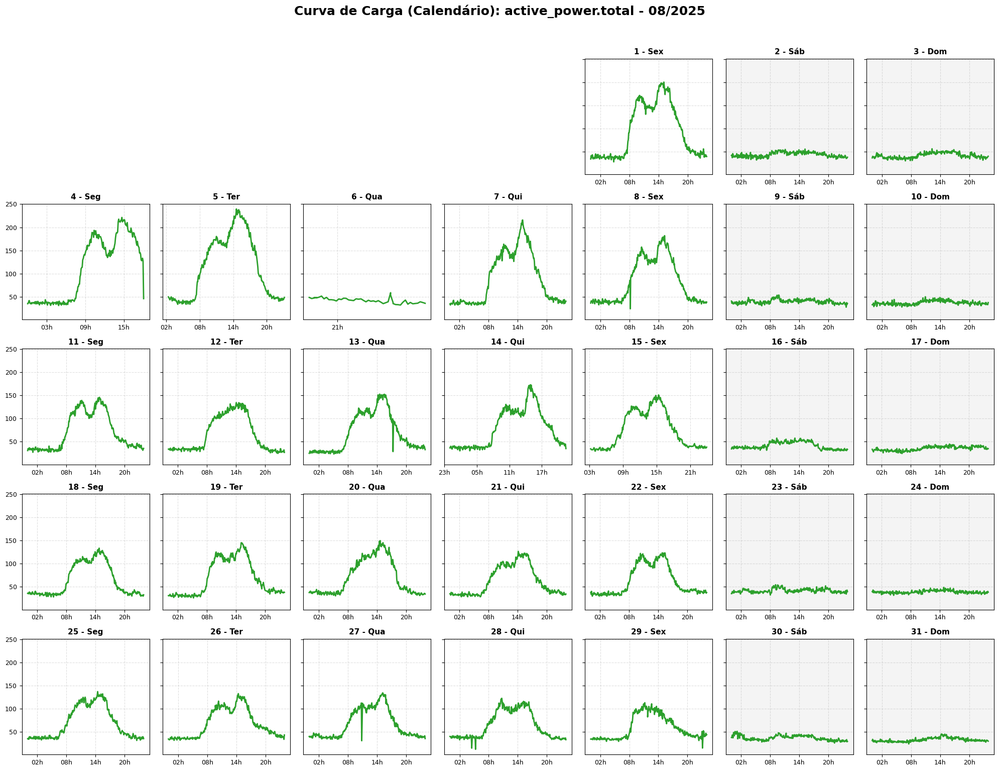

In [24]:

df_ccet = calcular_potencia_ativa_total(df_ccet)


df_ccet = preparar_dados_temporais(df_ccet, coluna_tempo='timestamp_leitura_anterior')

plotar_calendario_mensal(df_ccet, ano=2025, mes=8, coluna='active_power.total')


--- Processando: Medidor_BIO ---
⚡ Coluna 'active_power.total' calculada e adicionada com sucesso!
✅ Dados temporais tratados. Coluna 'dia_da_semana' adicionada e índice configurado.
Gerando gráfico: Medidor_BIO | 12/2025


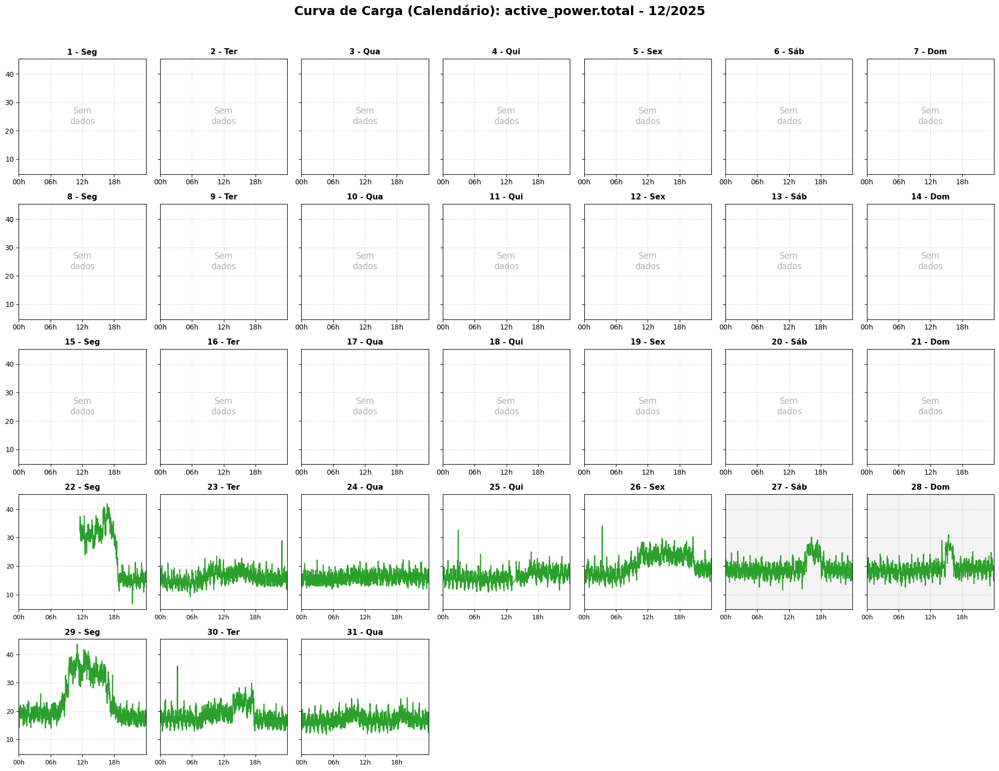

Gerando gráfico: Medidor_BIO | 03/2026


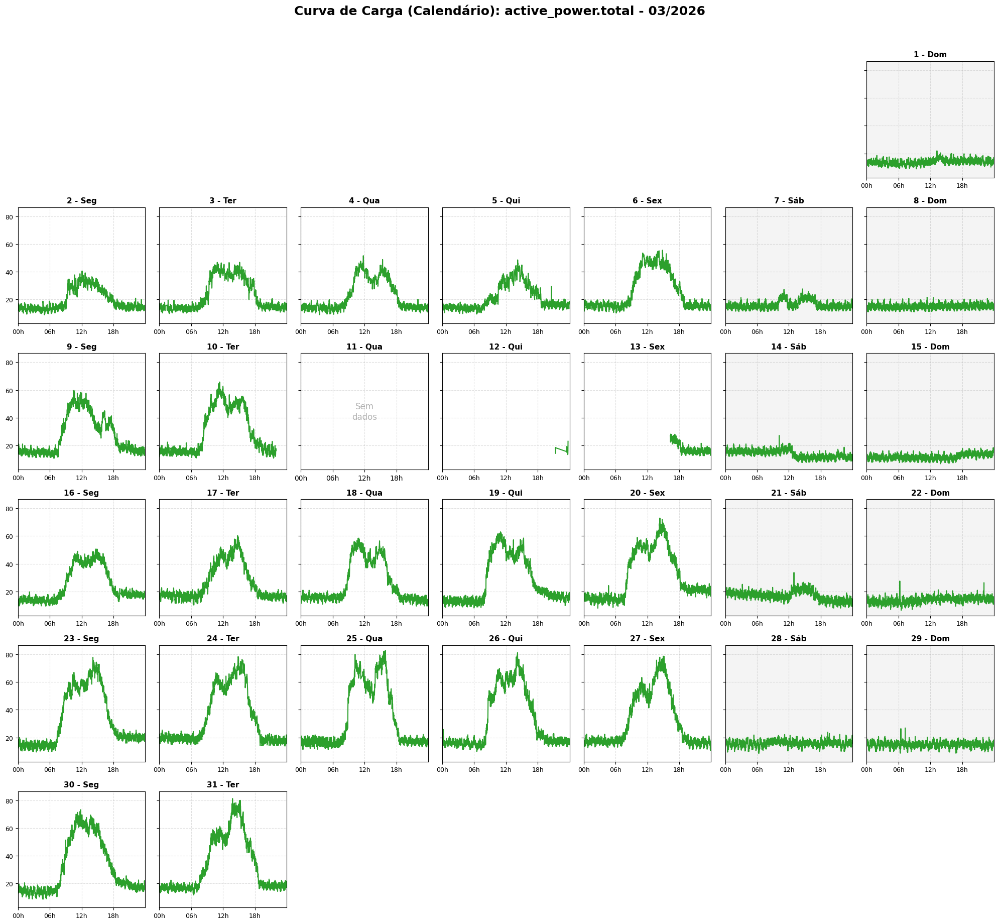

Gerando gráfico: Medidor_BIO | 04/2026


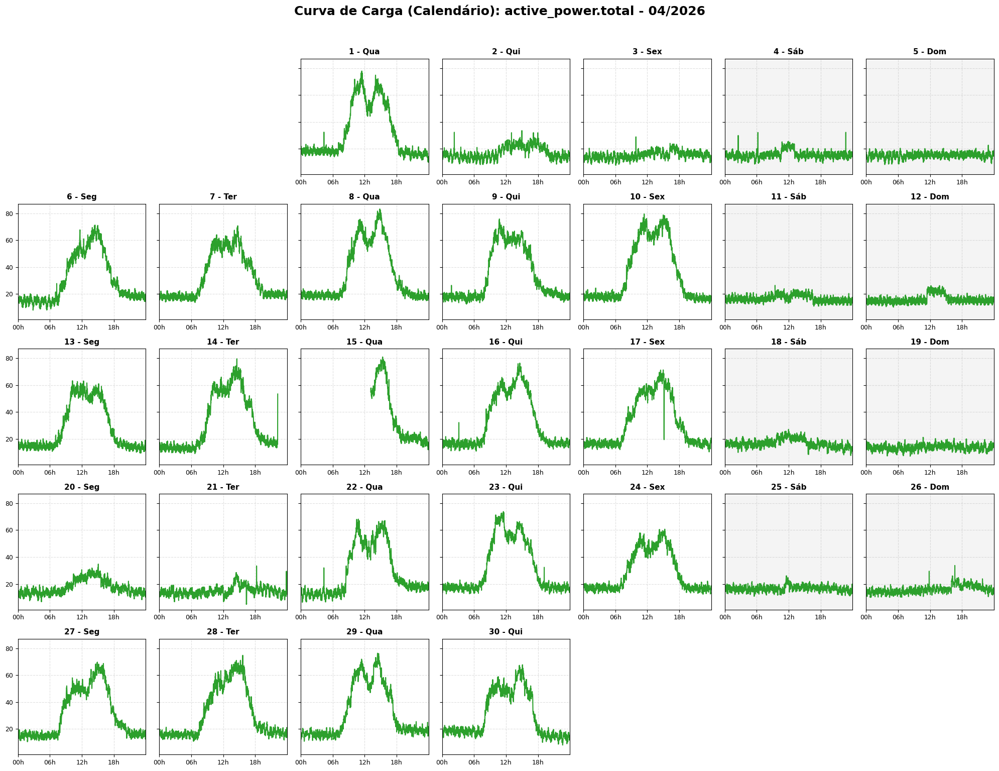

Gerando gráfico: Medidor_BIO | 10/2026


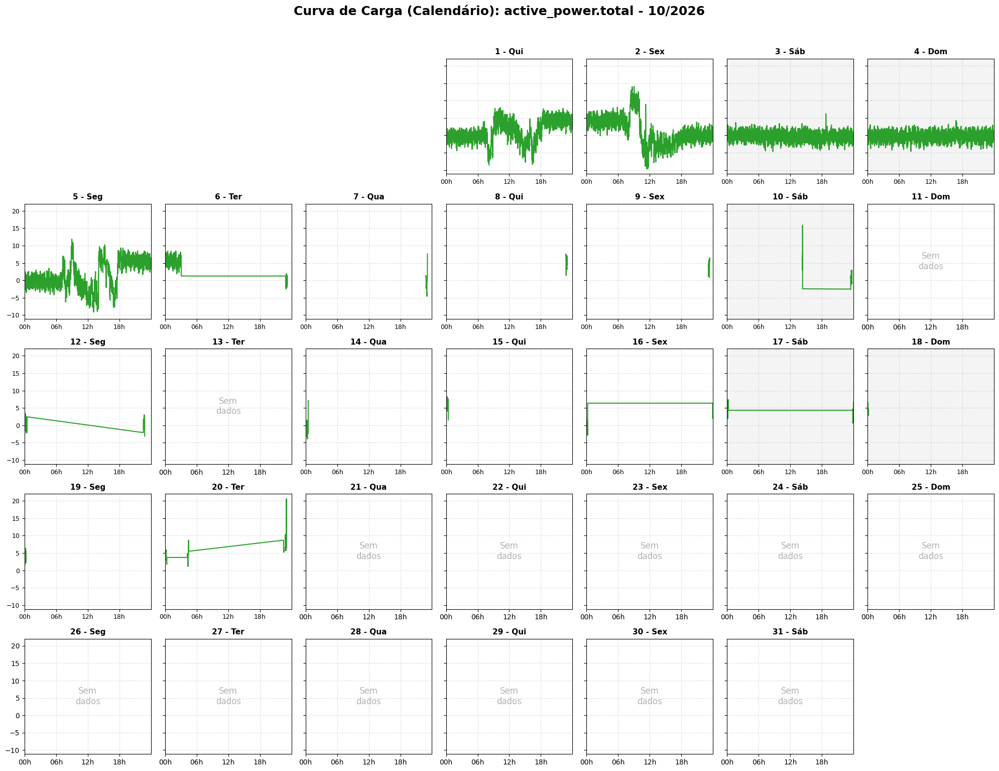


--- Processando: Medidor_CCH ---
⚡ Coluna 'active_power.total' calculada e adicionada com sucesso!
✅ Dados temporais tratados. Coluna 'dia_da_semana' adicionada e índice configurado.
Gerando gráfico: Medidor_CCH | 07/2025


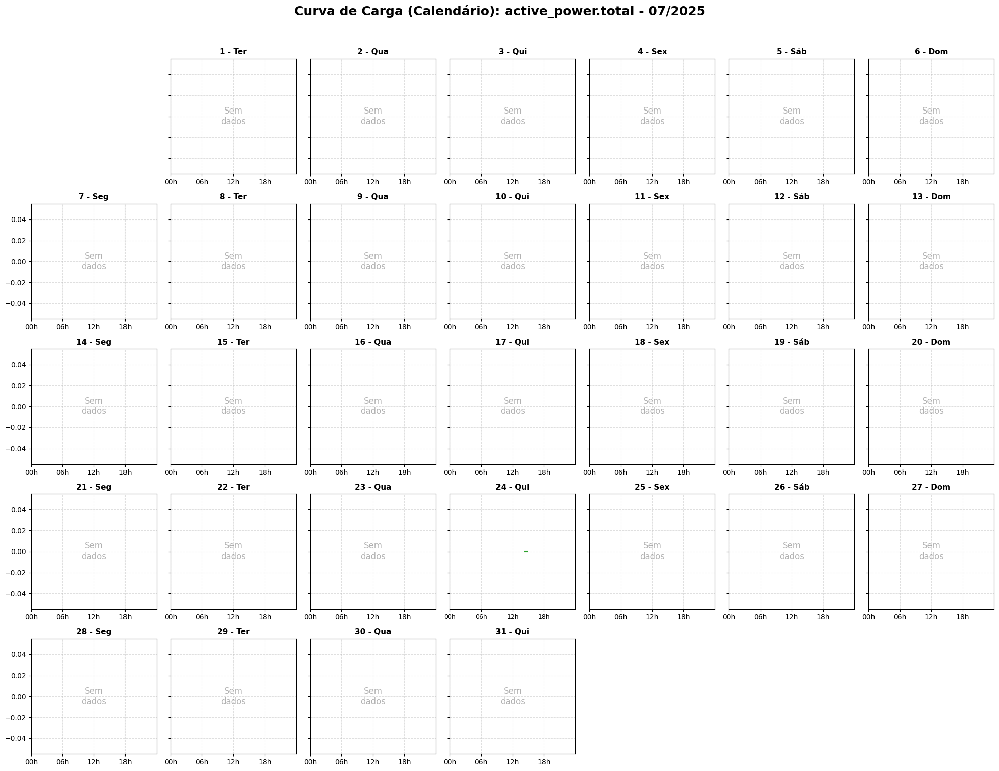

Gerando gráfico: Medidor_CCH | 08/2025


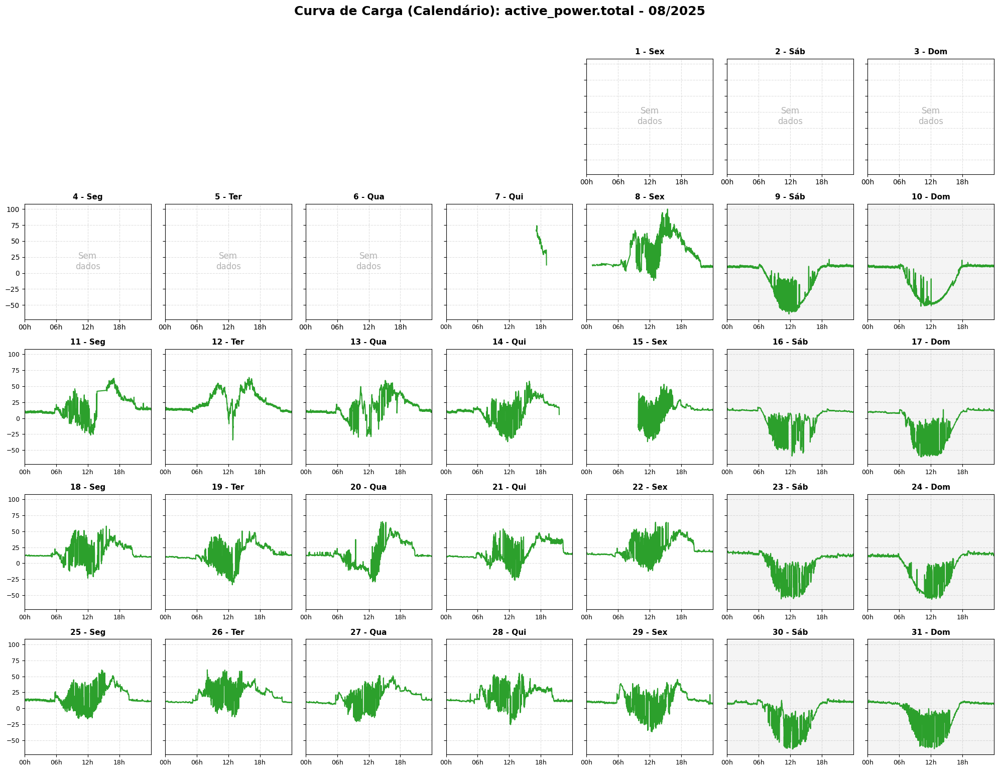

Gerando gráfico: Medidor_CCH | 09/2025


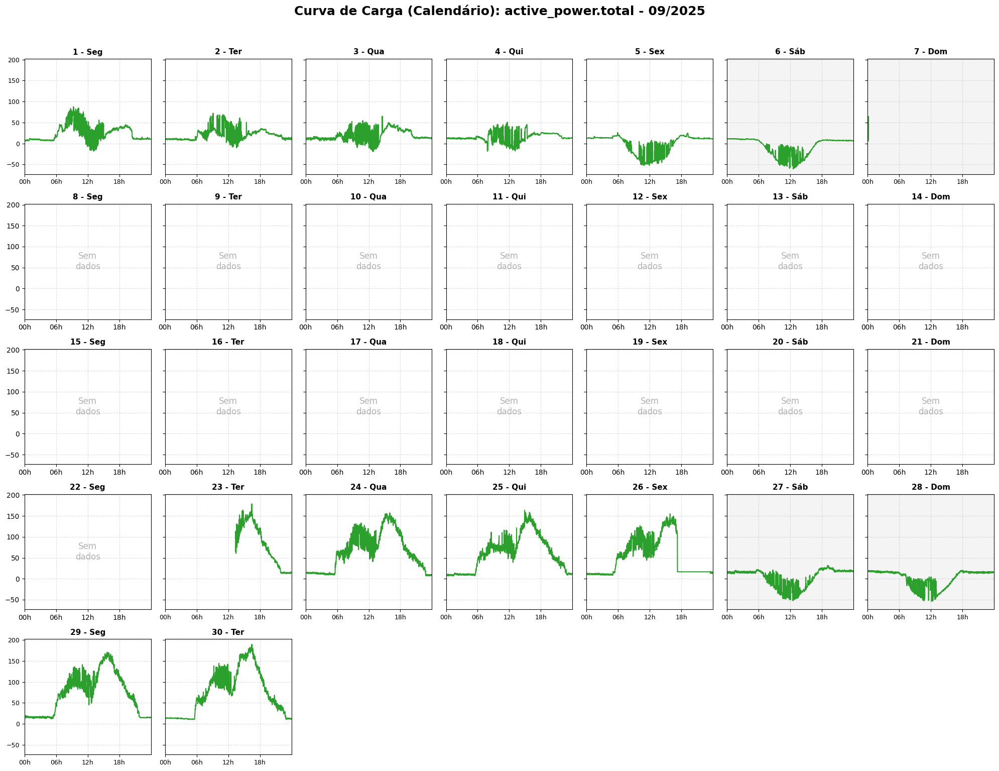

Gerando gráfico: Medidor_CCH | 11/2025


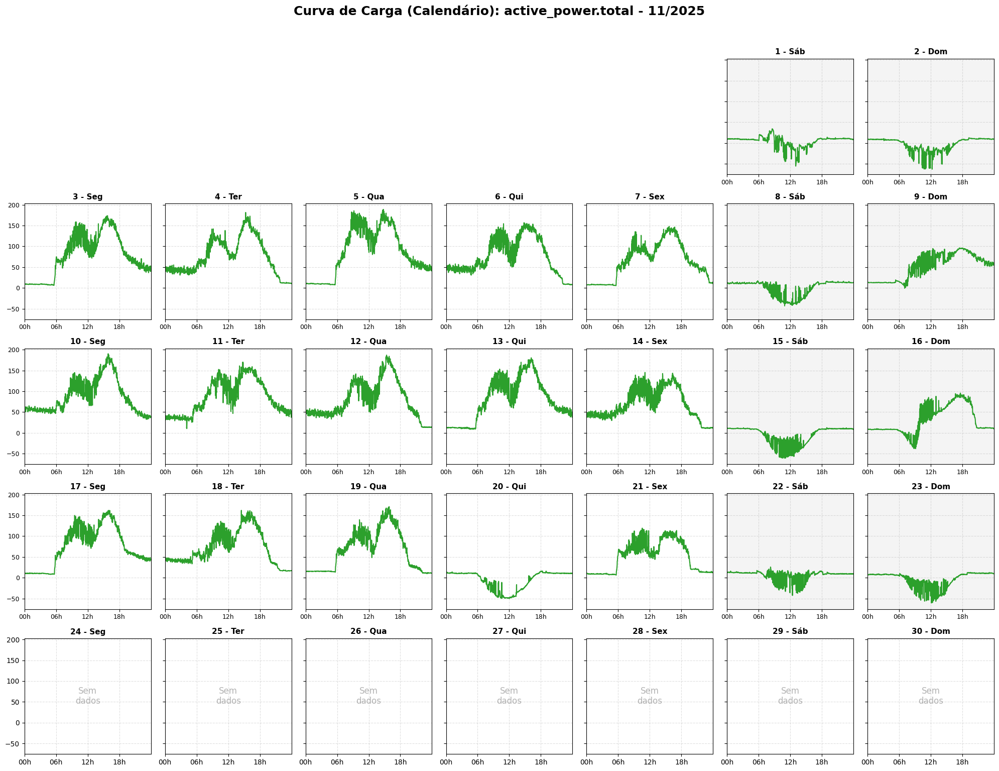

Gerando gráfico: Medidor_CCH | 12/2025


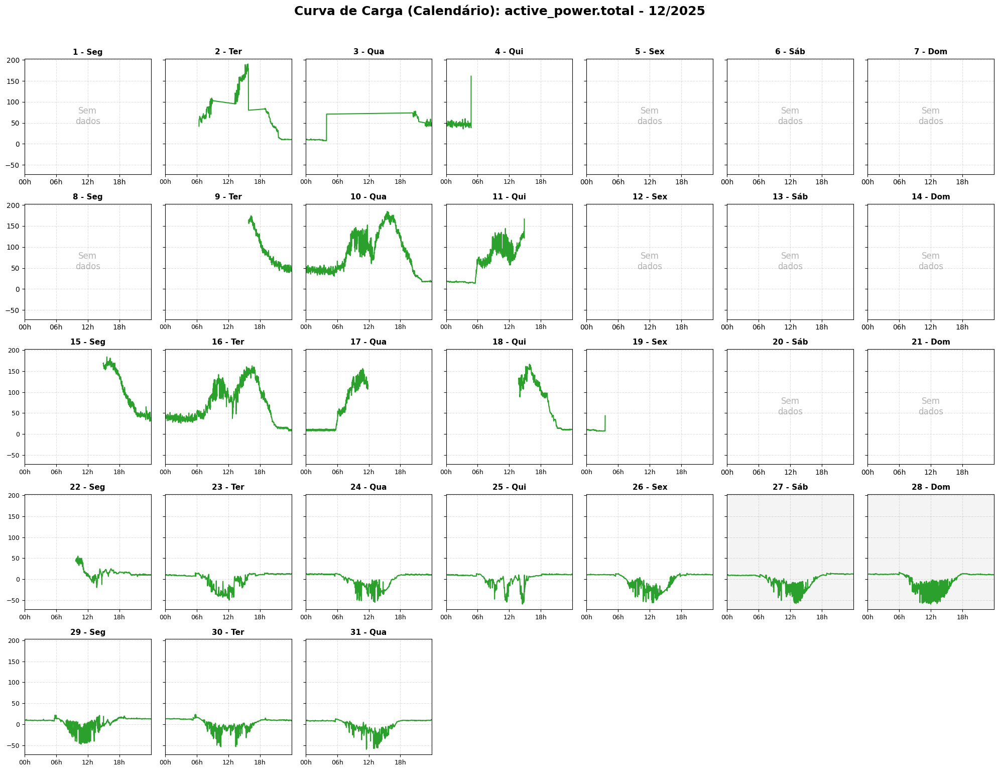

Gerando gráfico: Medidor_CCH | 03/2026


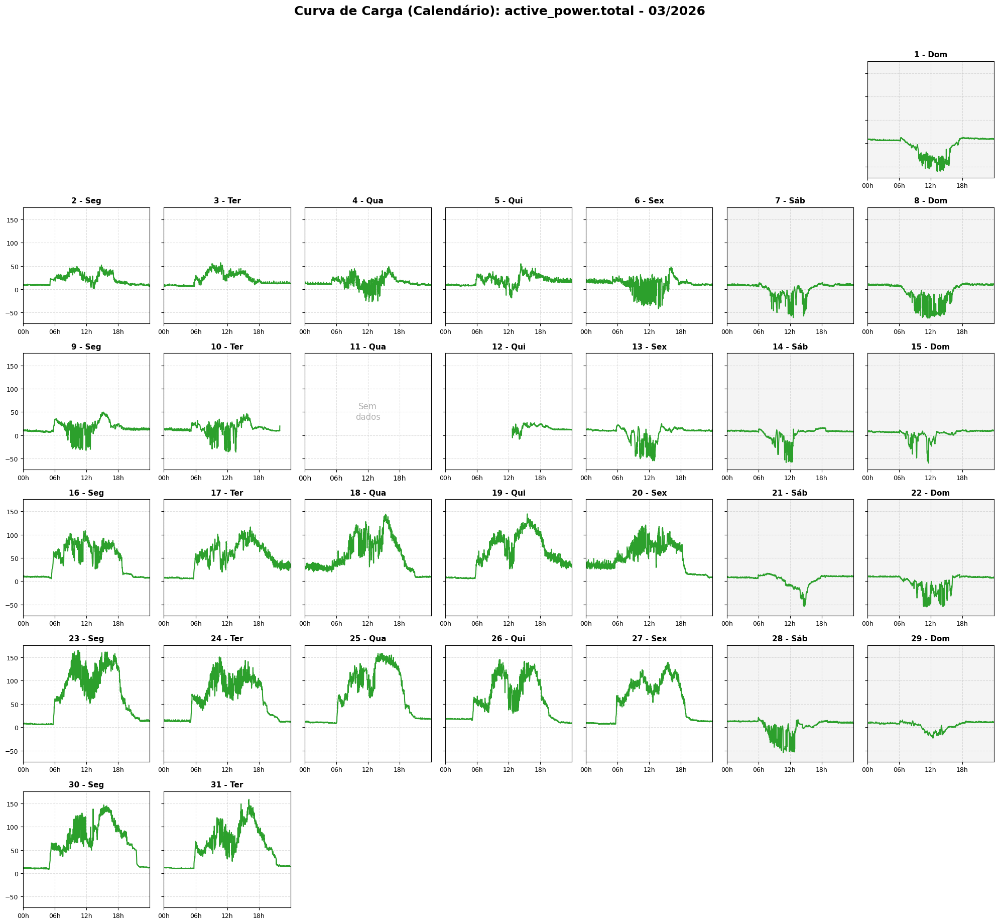

Gerando gráfico: Medidor_CCH | 04/2026


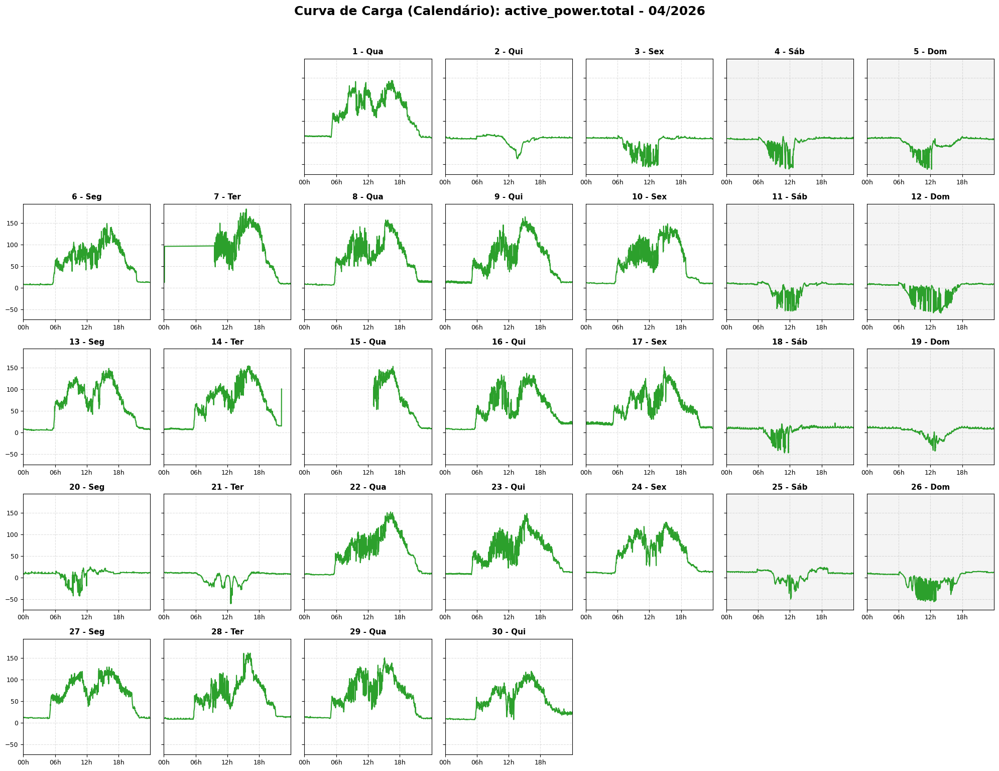

Gerando gráfico: Medidor_CCH | 10/2026


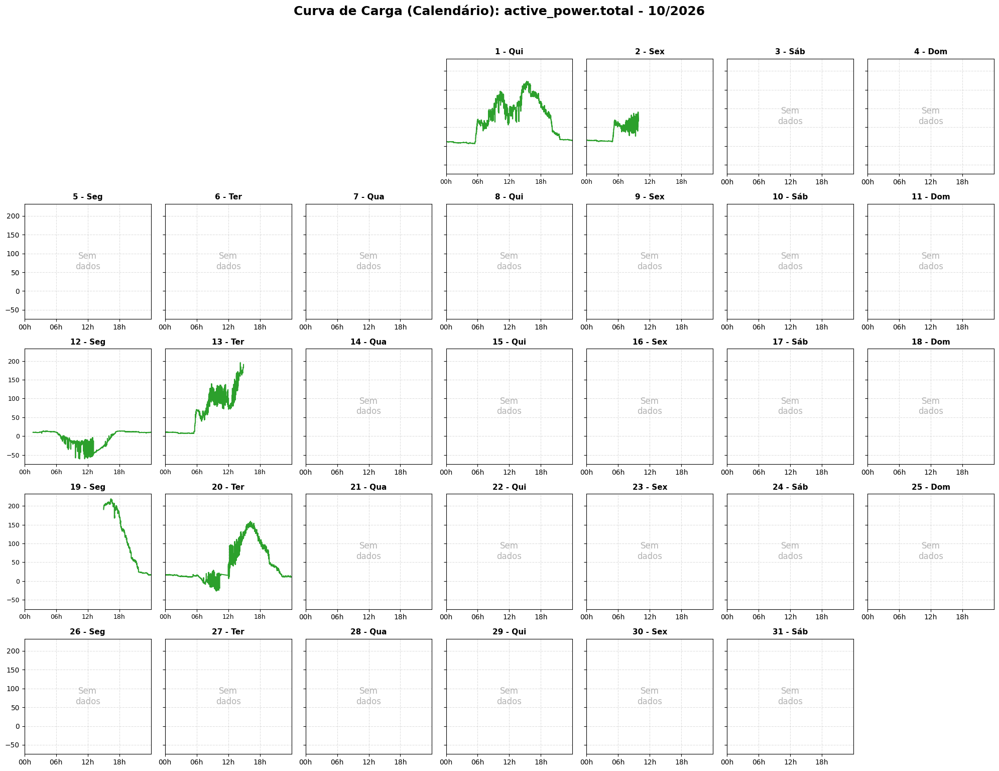


--- Processando: Medidor_CCSO ---
⚡ Coluna 'active_power.total' calculada e adicionada com sucesso!
✅ Dados temporais tratados. Coluna 'dia_da_semana' adicionada e índice configurado.
Gerando gráfico: Medidor_CCSO | 07/2025


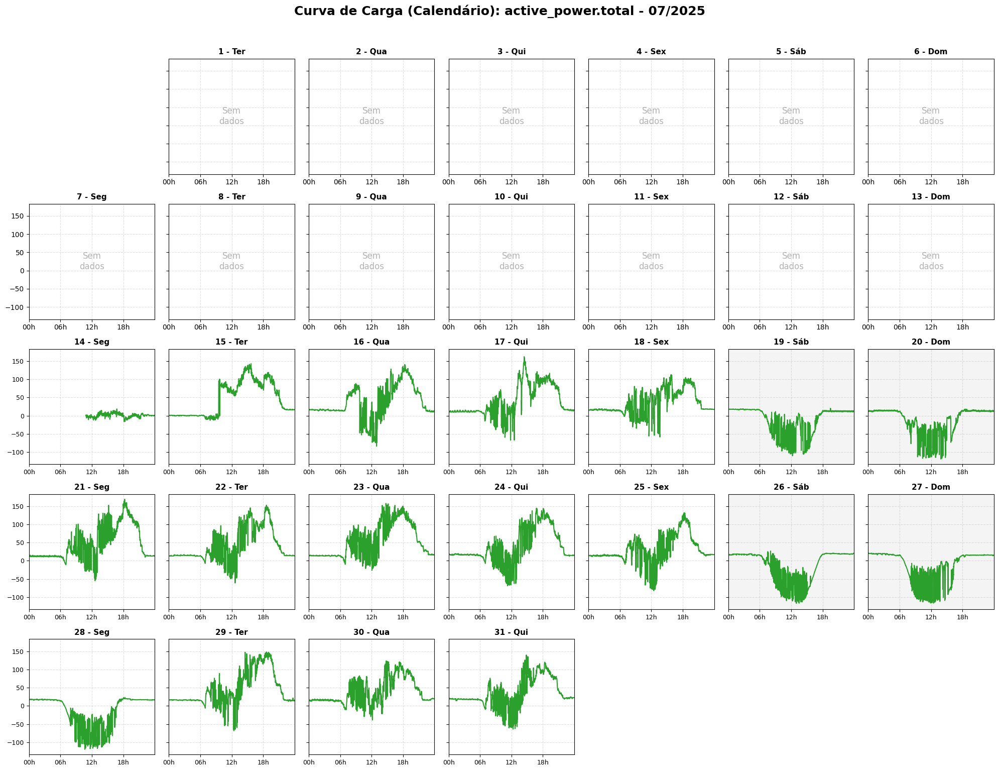

Gerando gráfico: Medidor_CCSO | 08/2025


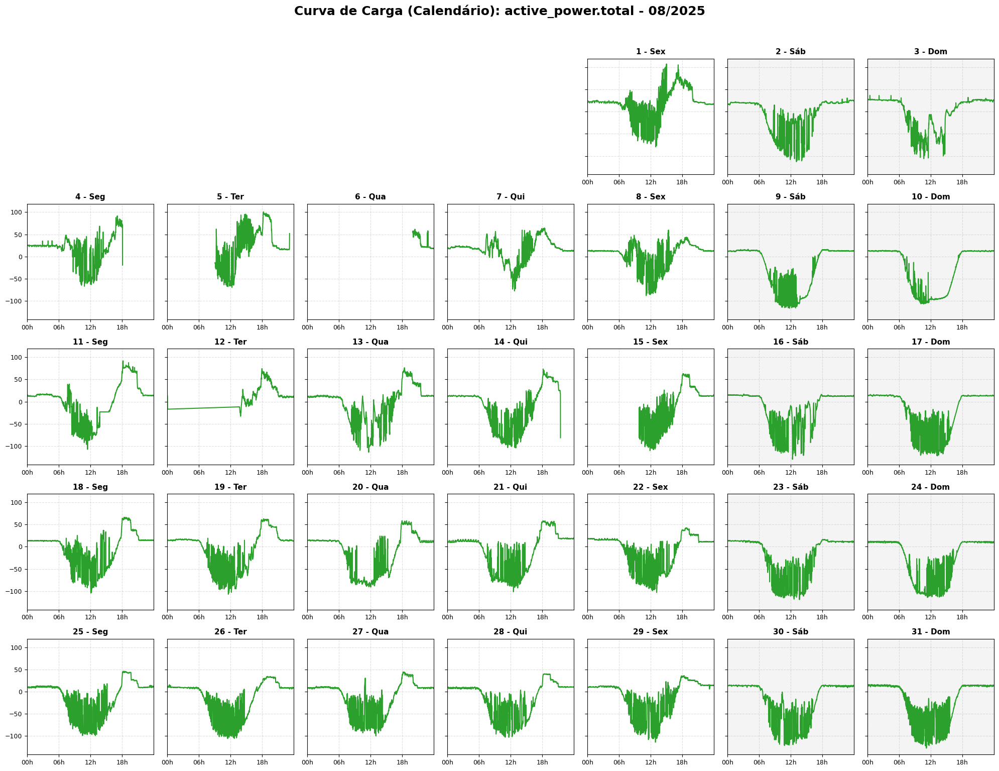

Gerando gráfico: Medidor_CCSO | 09/2025


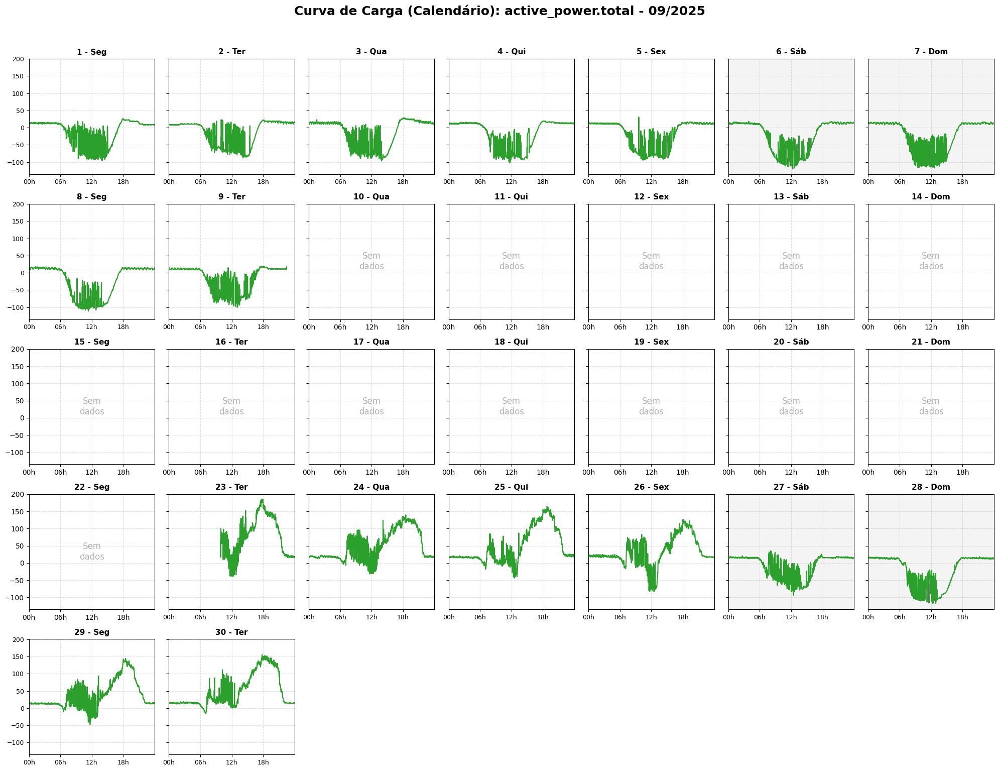

Gerando gráfico: Medidor_CCSO | 11/2025


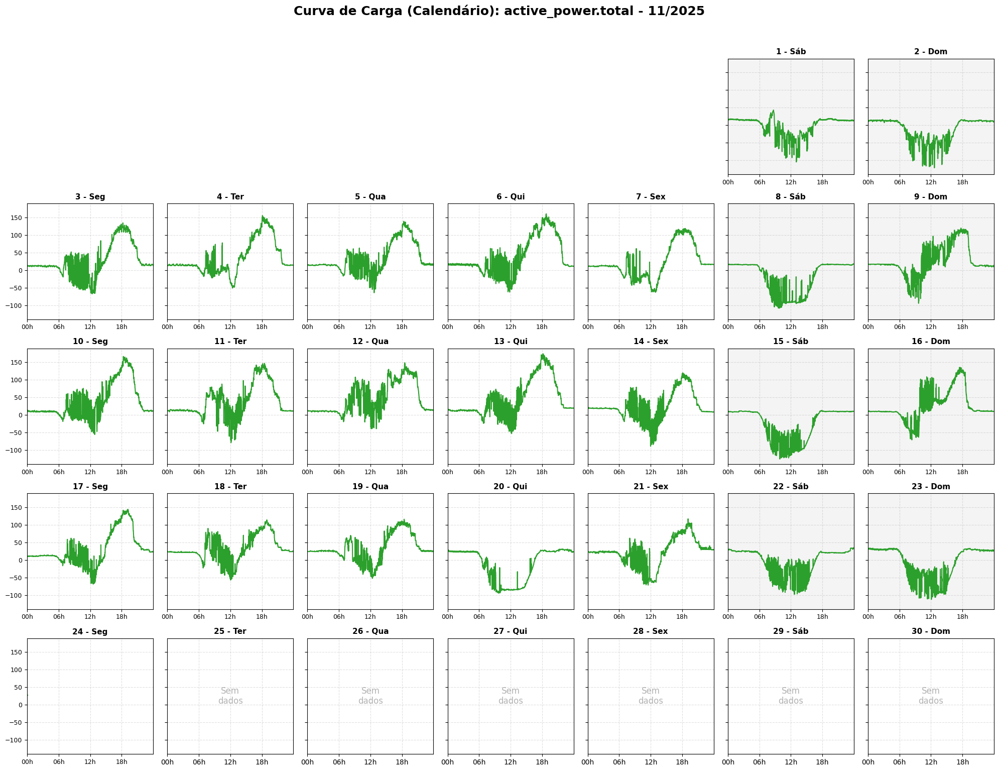

Gerando gráfico: Medidor_CCSO | 12/2025


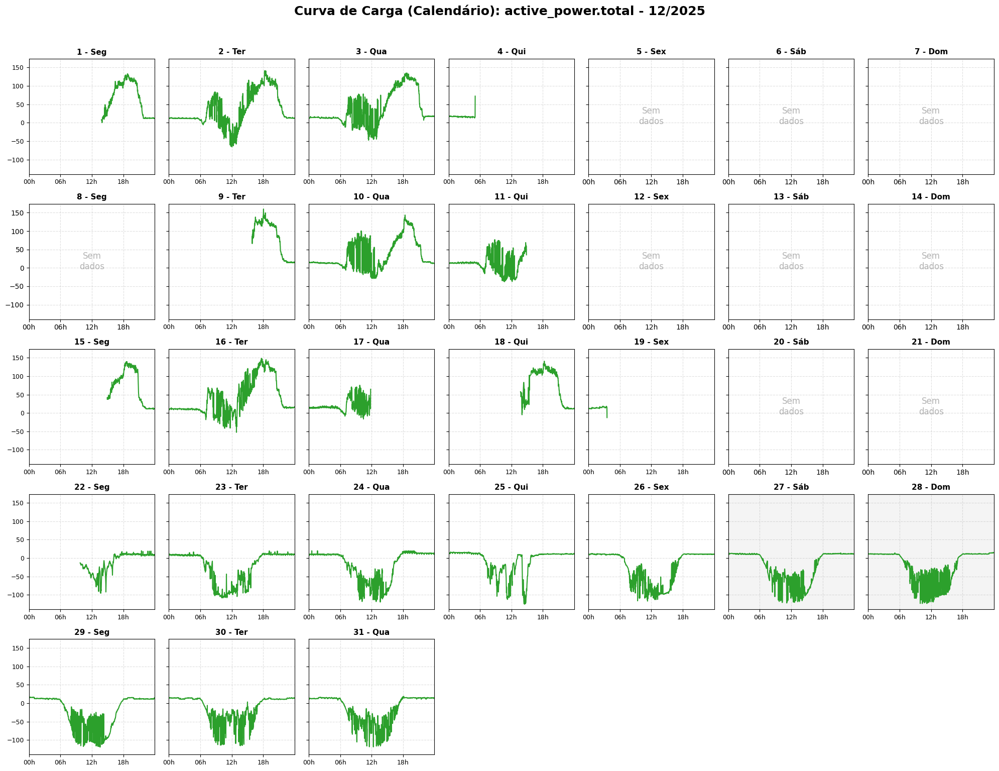

Gerando gráfico: Medidor_CCSO | 03/2026


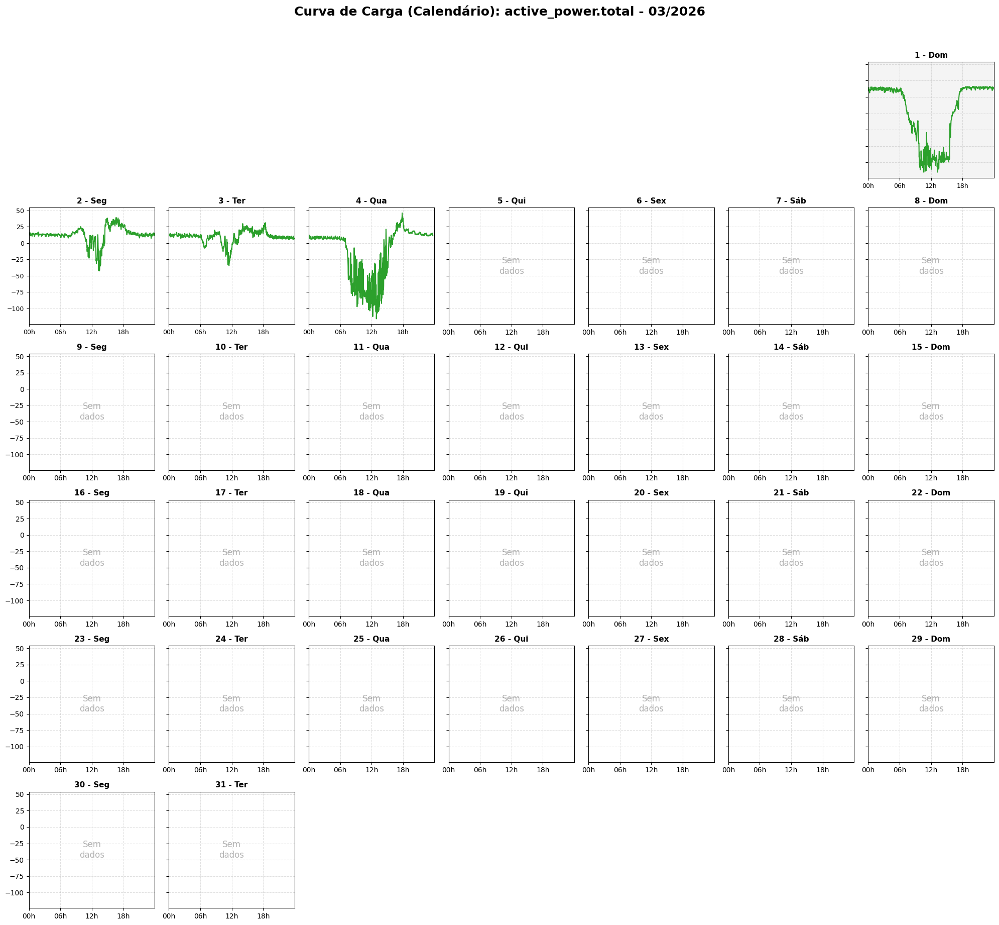

Gerando gráfico: Medidor_CCSO | 10/2026


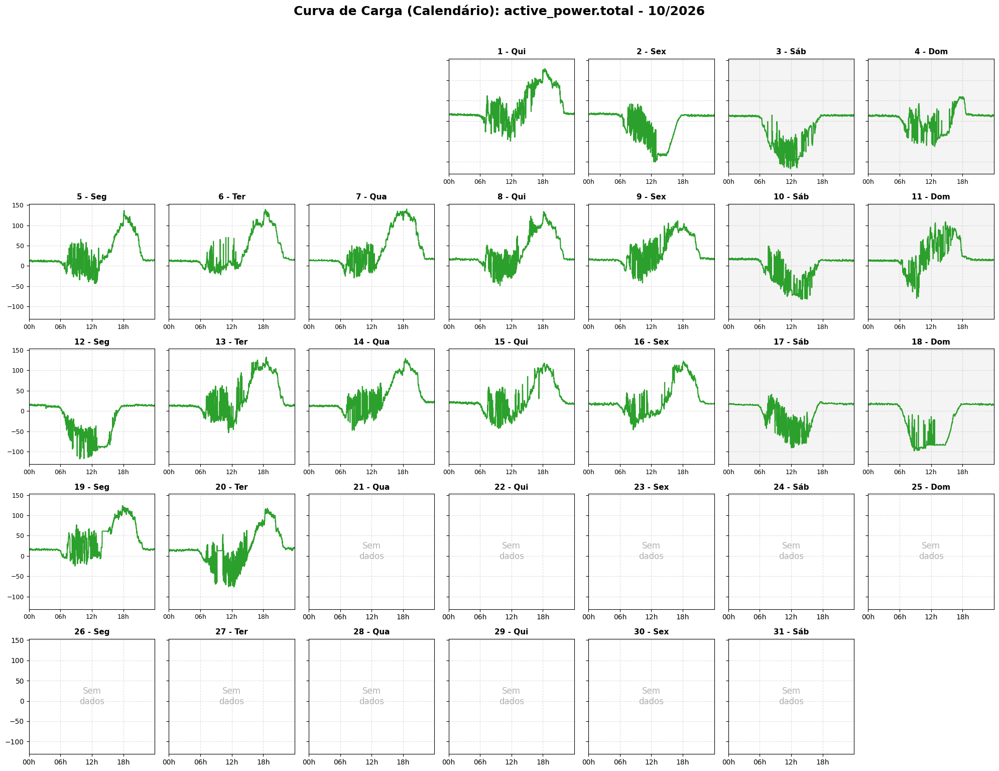


--- Processando: Medidor_IEE ---
⚡ Coluna 'active_power.total' calculada e adicionada com sucesso!
✅ Dados temporais tratados. Coluna 'dia_da_semana' adicionada e índice configurado.
Gerando gráfico: Medidor_IEE | 01/2025


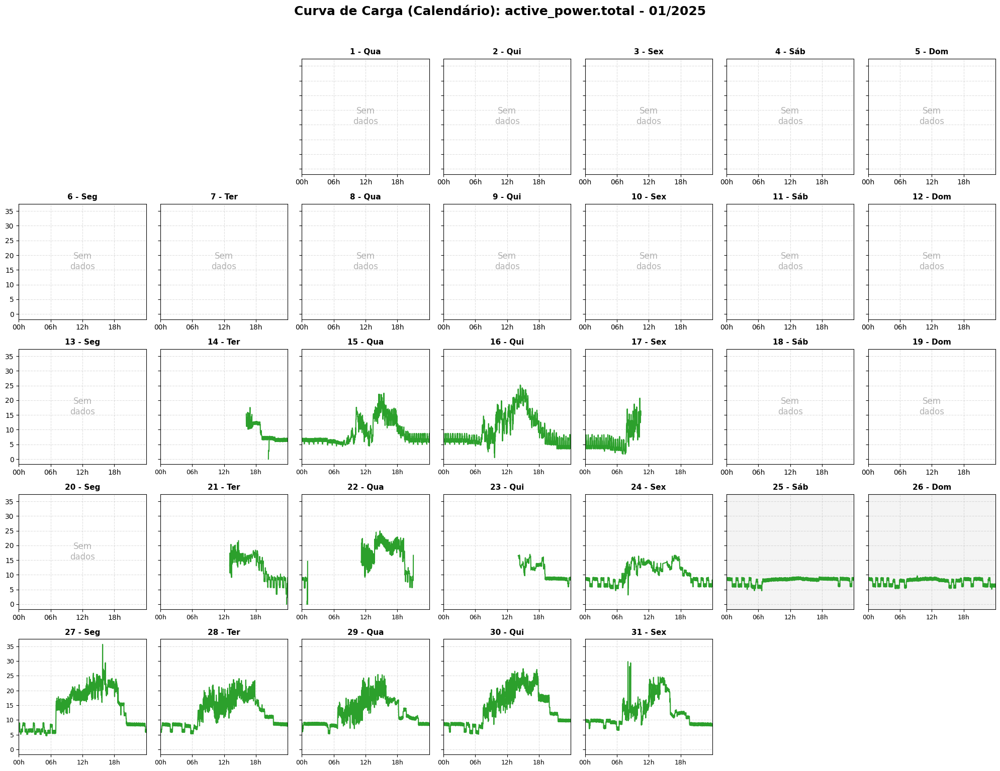

Gerando gráfico: Medidor_IEE | 03/2025


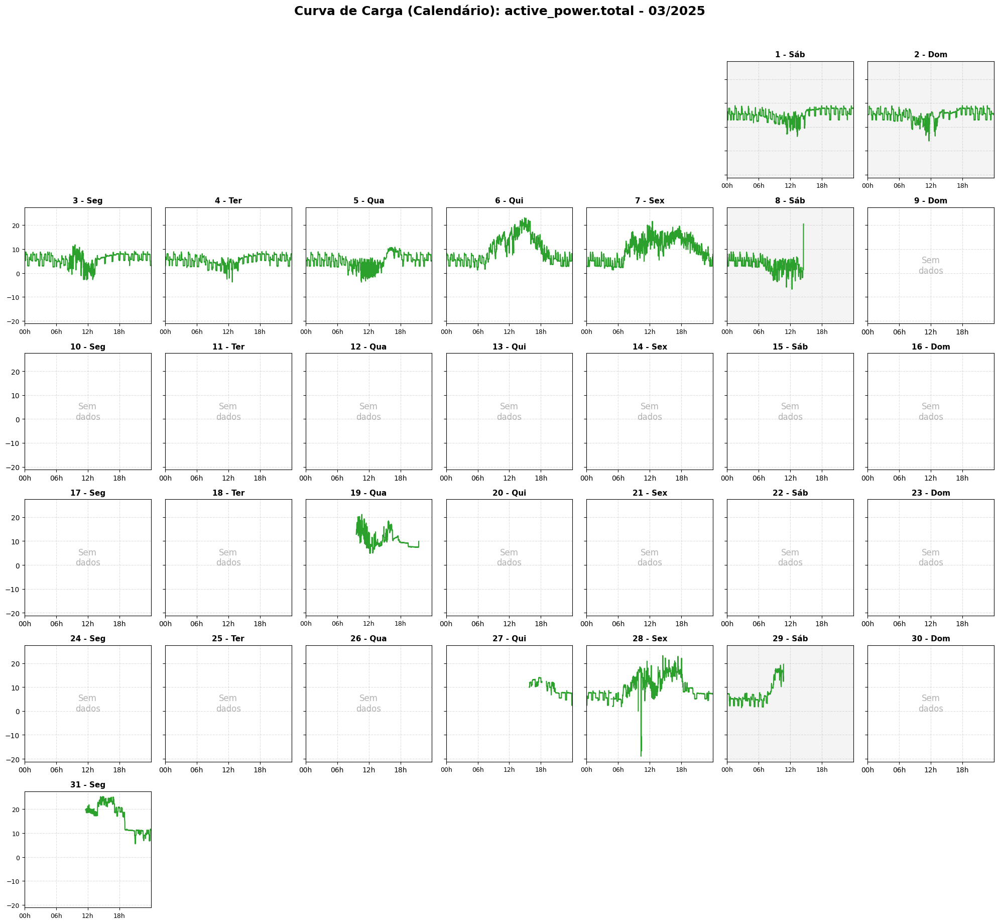

Gerando gráfico: Medidor_IEE | 06/2025


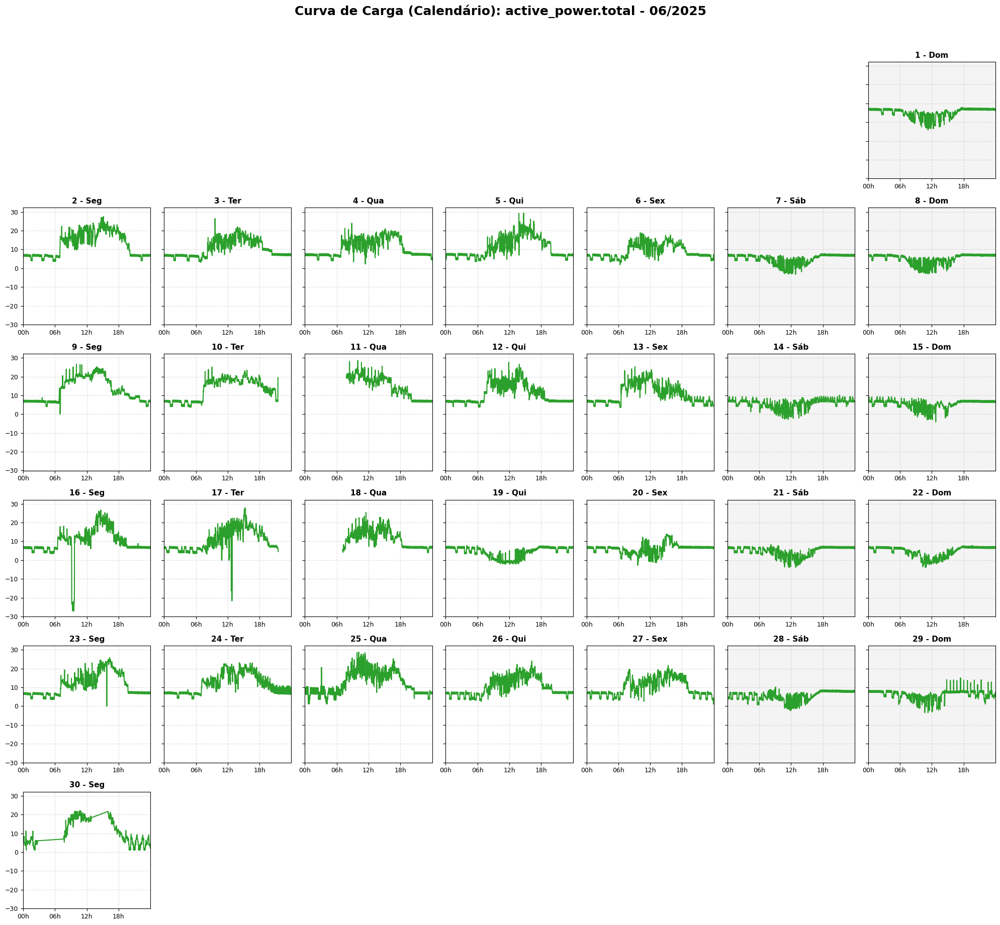

Gerando gráfico: Medidor_IEE | 07/2025


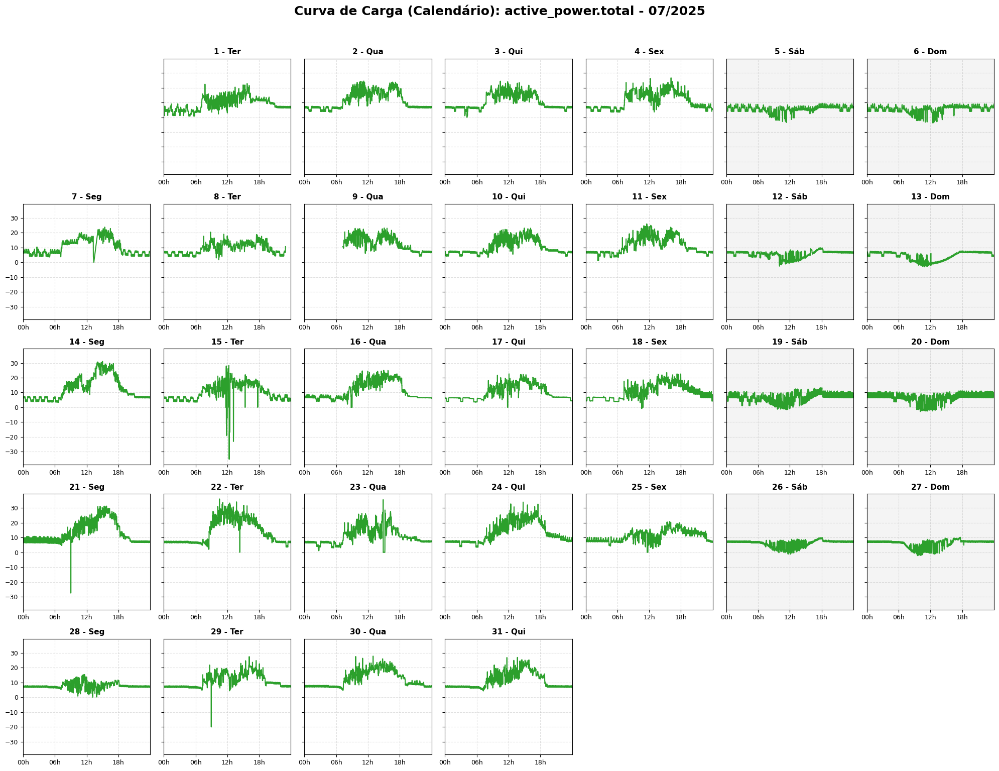

Gerando gráfico: Medidor_IEE | 08/2025


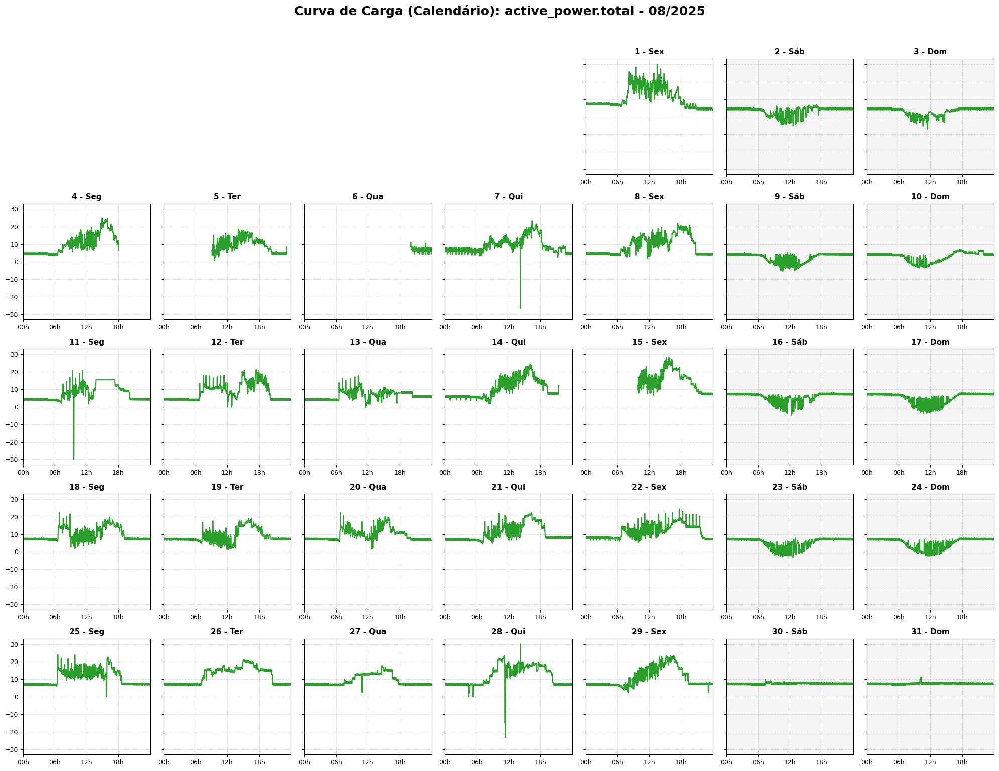

Gerando gráfico: Medidor_IEE | 09/2025


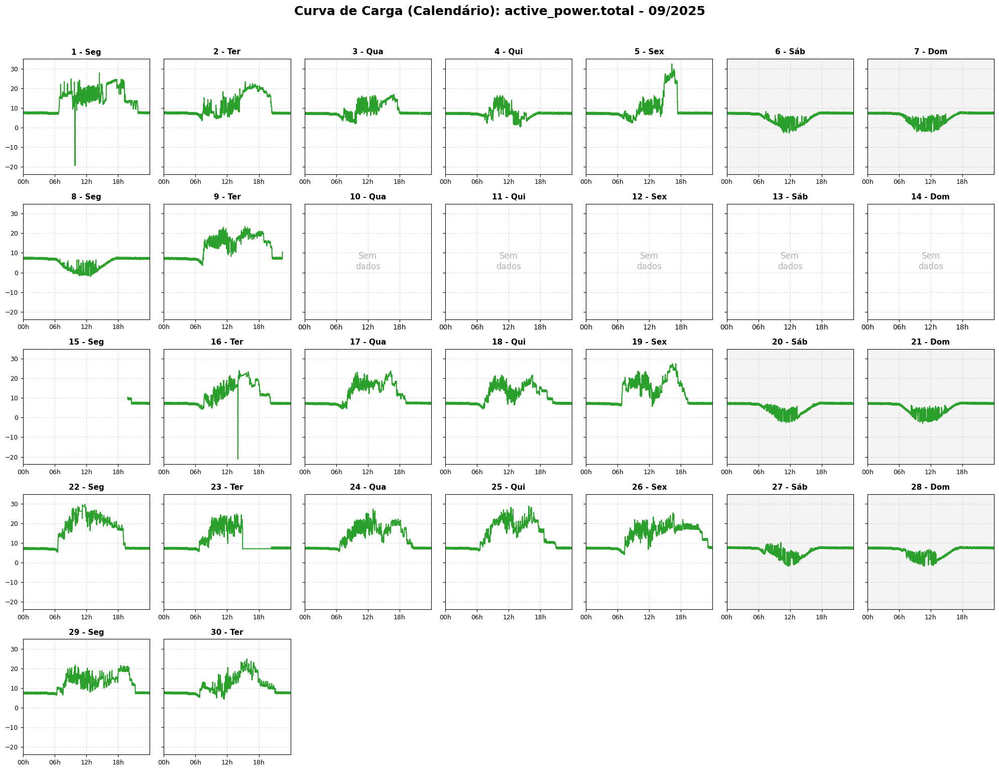

Gerando gráfico: Medidor_IEE | 11/2025


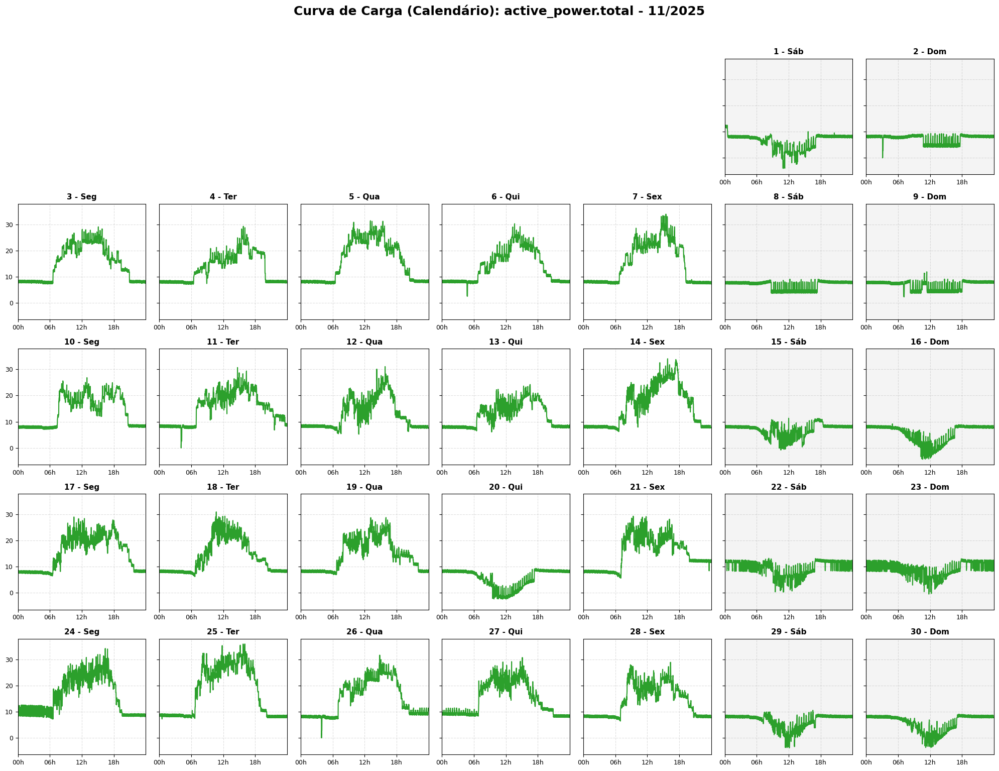

Gerando gráfico: Medidor_IEE | 12/2025


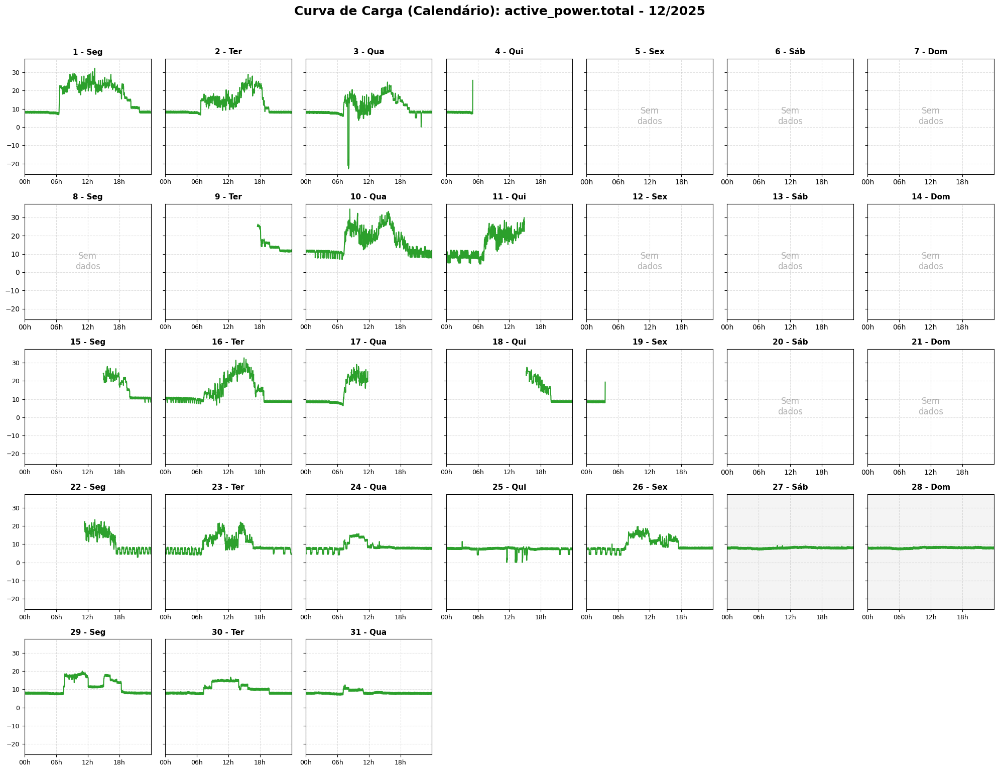

Gerando gráfico: Medidor_IEE | 10/2026


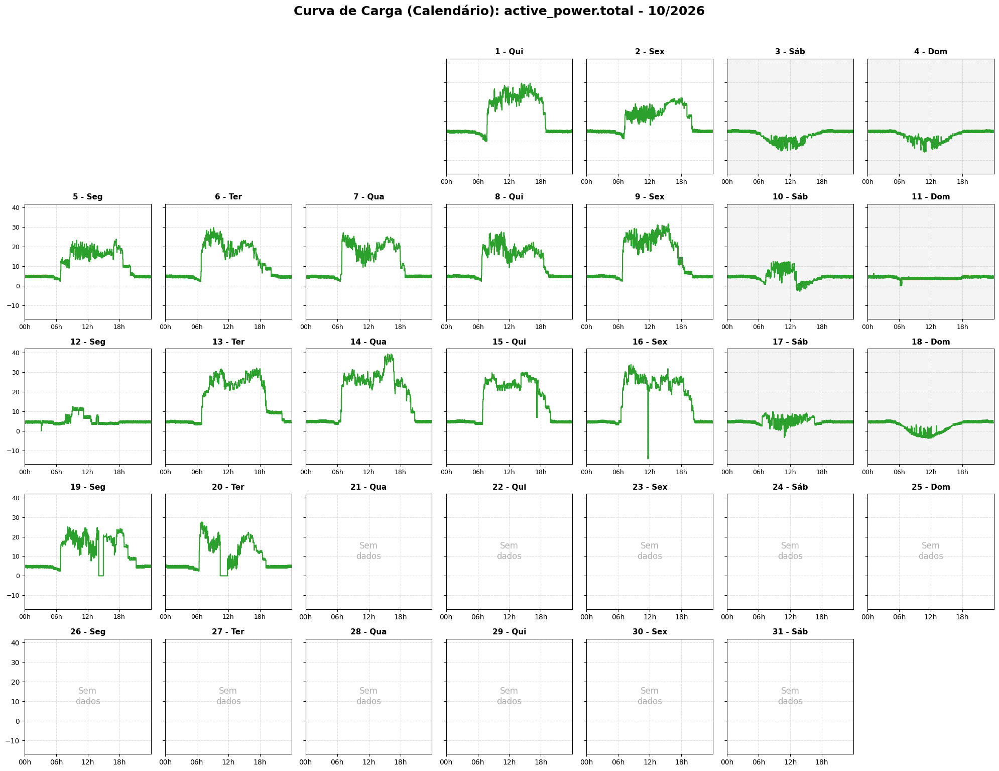


--- Processando: Medidor_ODONTO ---
⚡ Coluna 'active_power.total' calculada e adicionada com sucesso!
✅ Dados temporais tratados. Coluna 'dia_da_semana' adicionada e índice configurado.
Gerando gráfico: Medidor_ODONTO | 07/2025


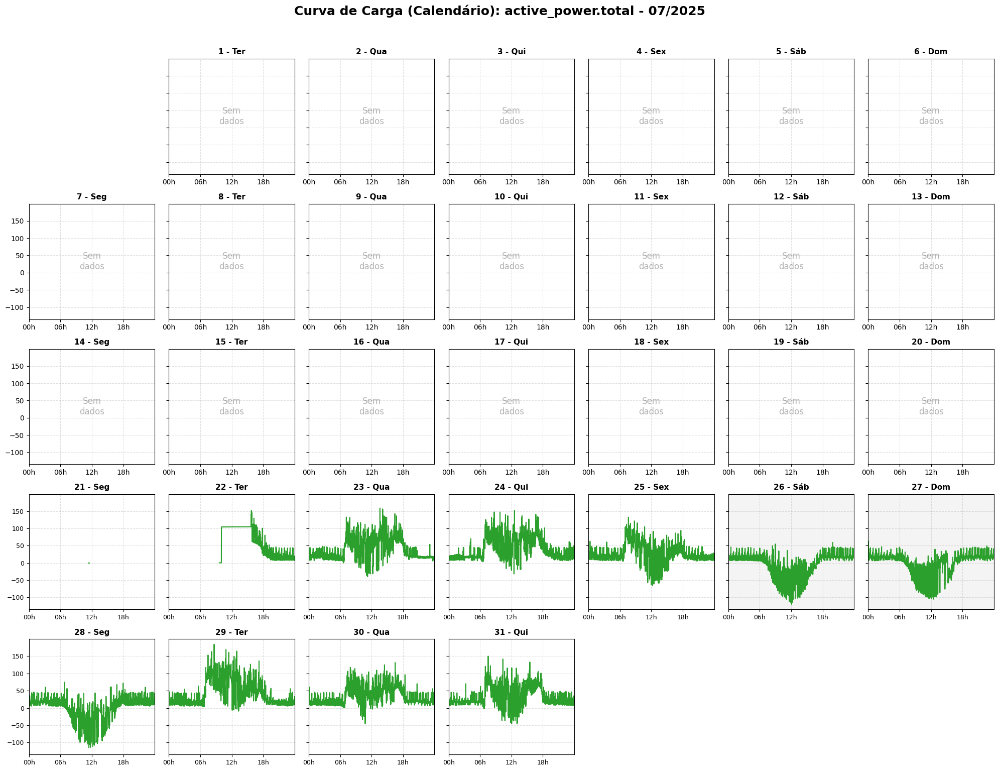

Gerando gráfico: Medidor_ODONTO | 08/2025


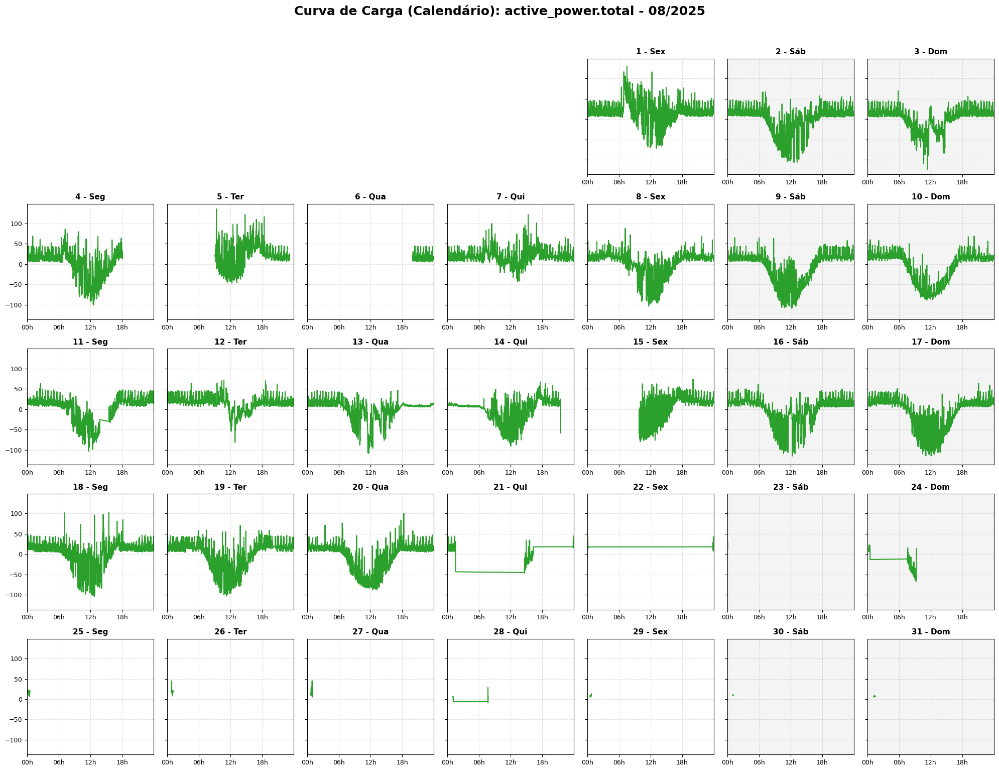

Gerando gráfico: Medidor_ODONTO | 09/2025


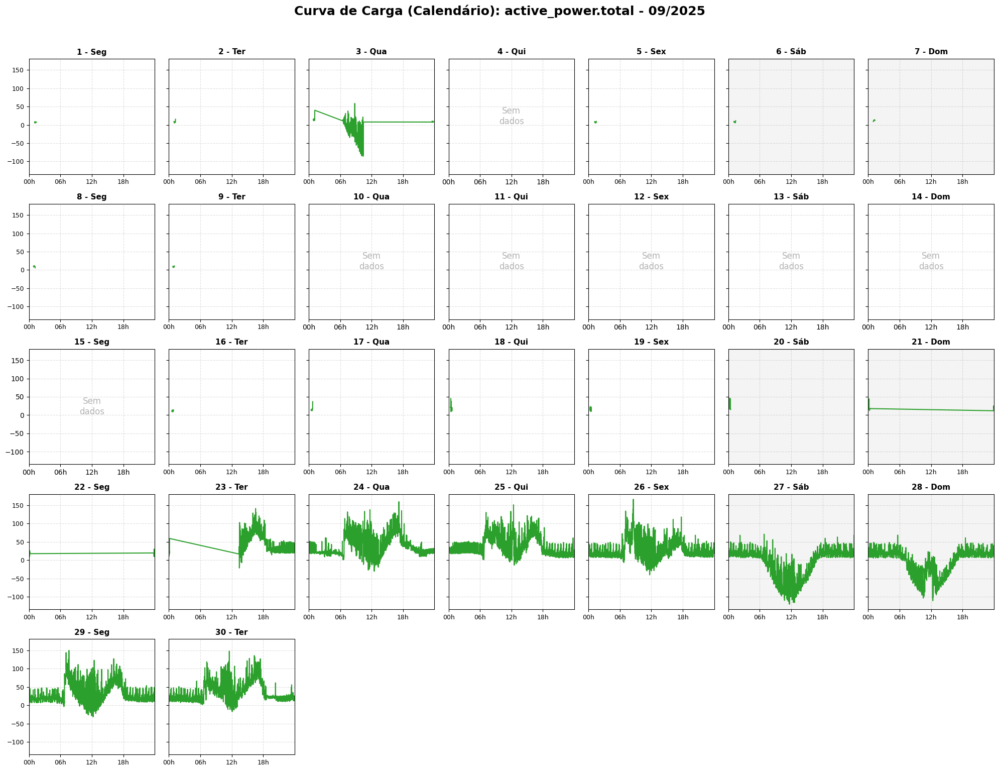

Gerando gráfico: Medidor_ODONTO | 11/2025


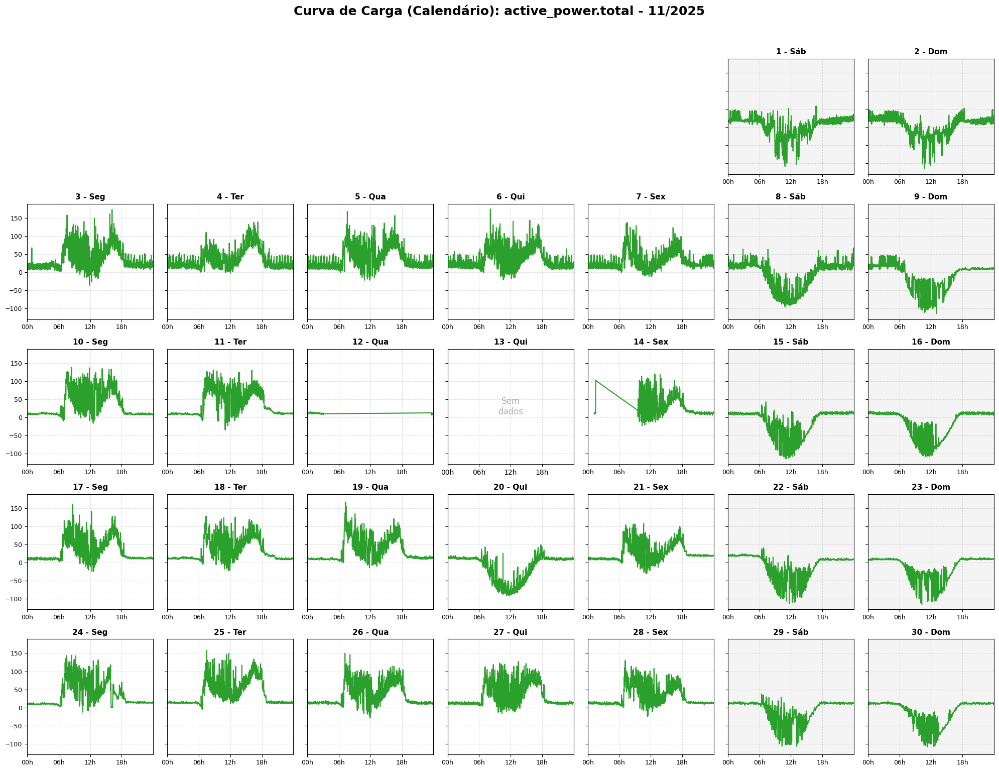

Gerando gráfico: Medidor_ODONTO | 12/2025


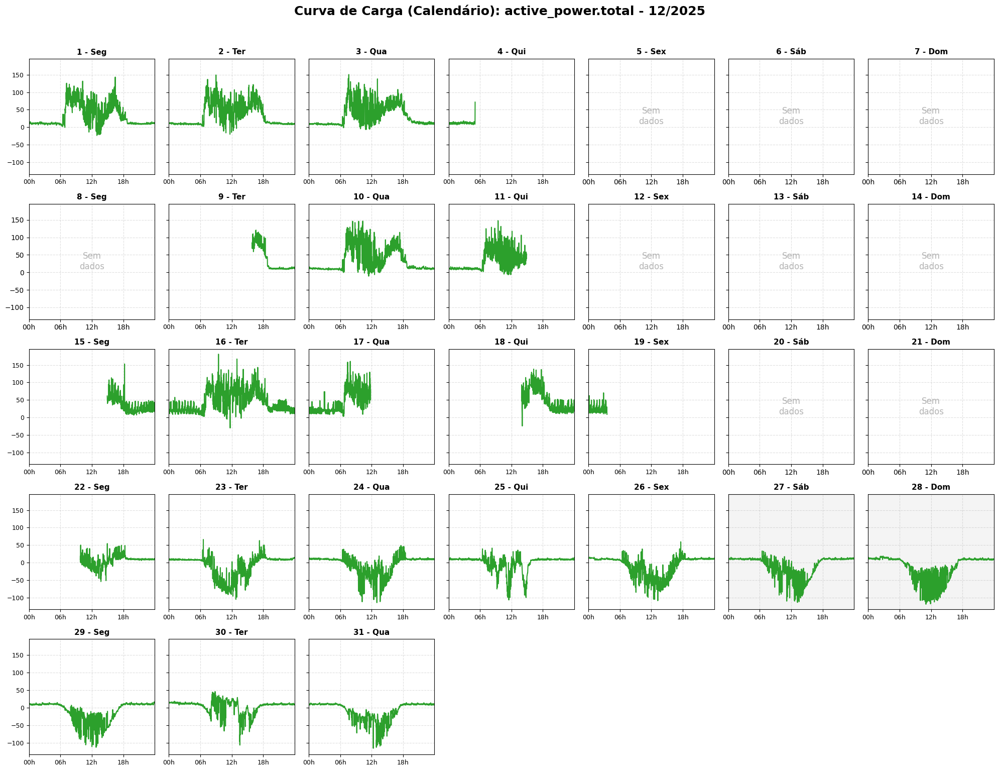

Gerando gráfico: Medidor_ODONTO | 03/2026


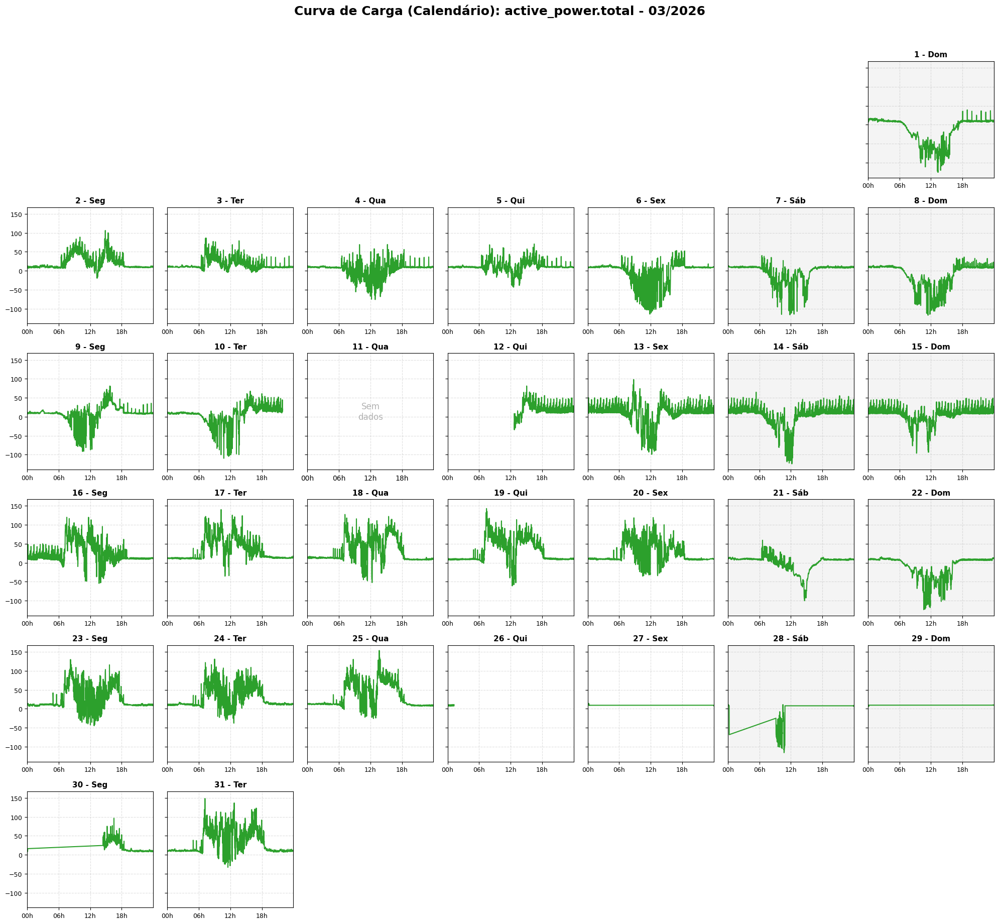

Gerando gráfico: Medidor_ODONTO | 04/2026


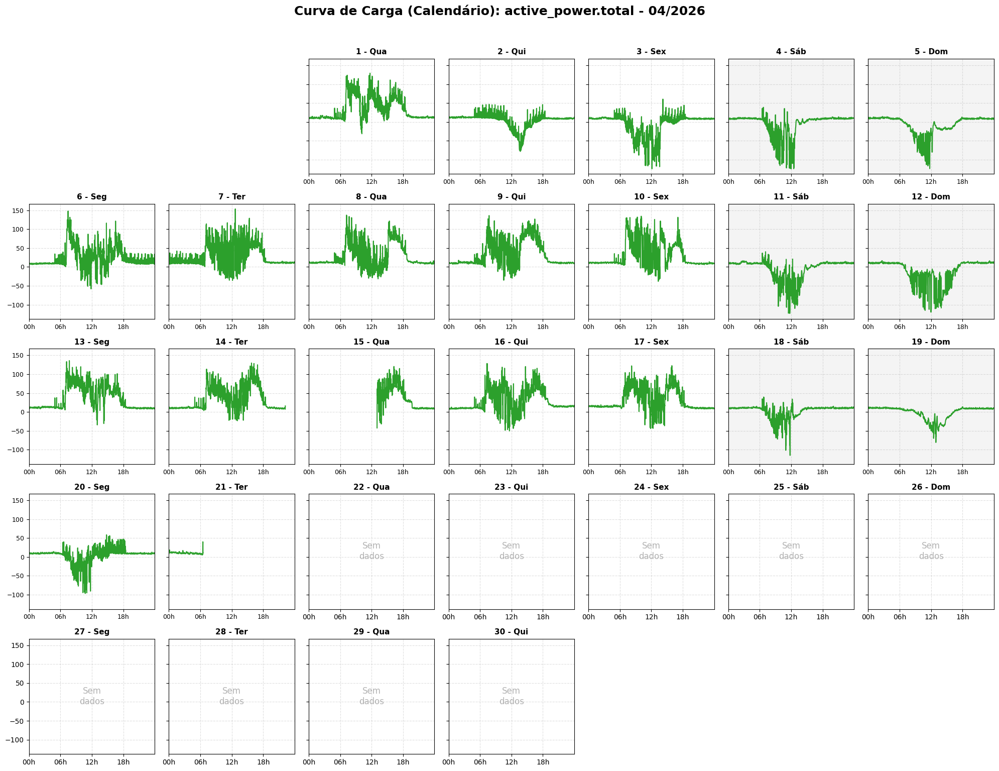

Gerando gráfico: Medidor_ODONTO | 10/2026


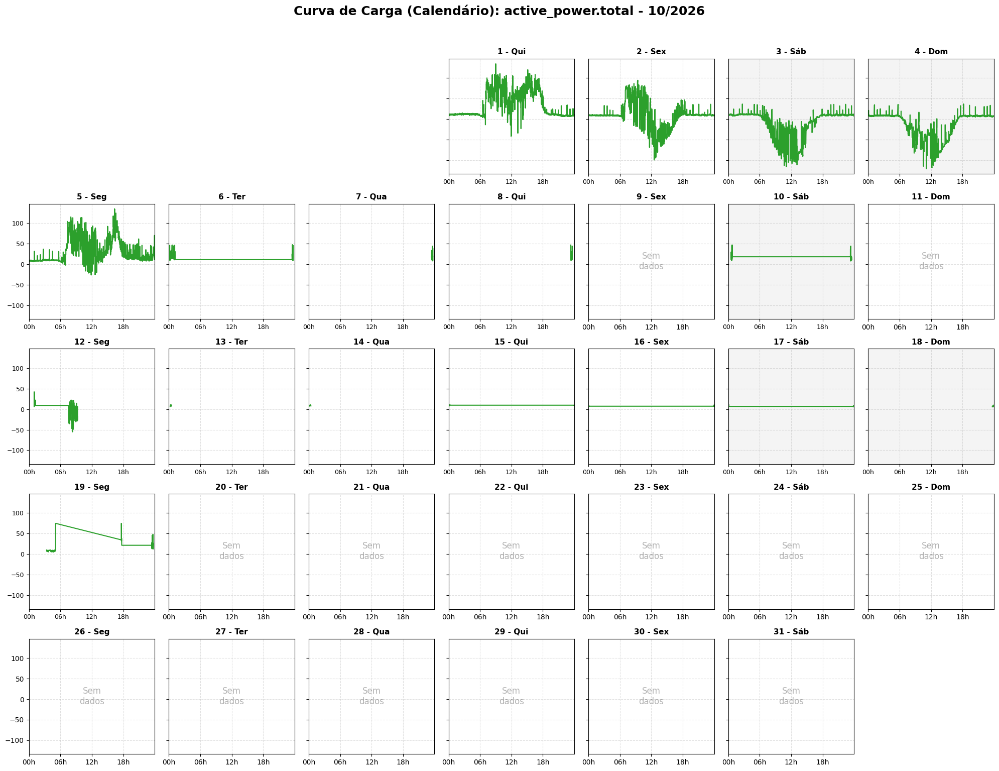


--- Processando: Medidor_PF ---
⚡ Coluna 'active_power.total' calculada e adicionada com sucesso!
✅ Dados temporais tratados. Coluna 'dia_da_semana' adicionada e índice configurado.
Gerando gráfico: Medidor_PF | 01/2025


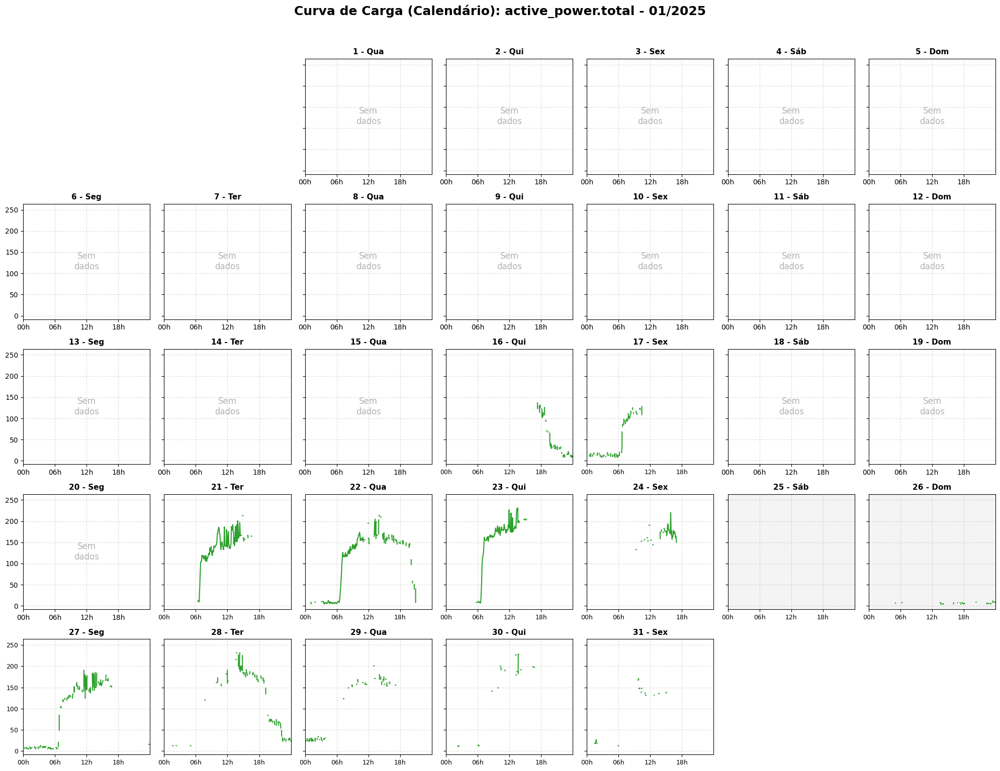

Gerando gráfico: Medidor_PF | 03/2025


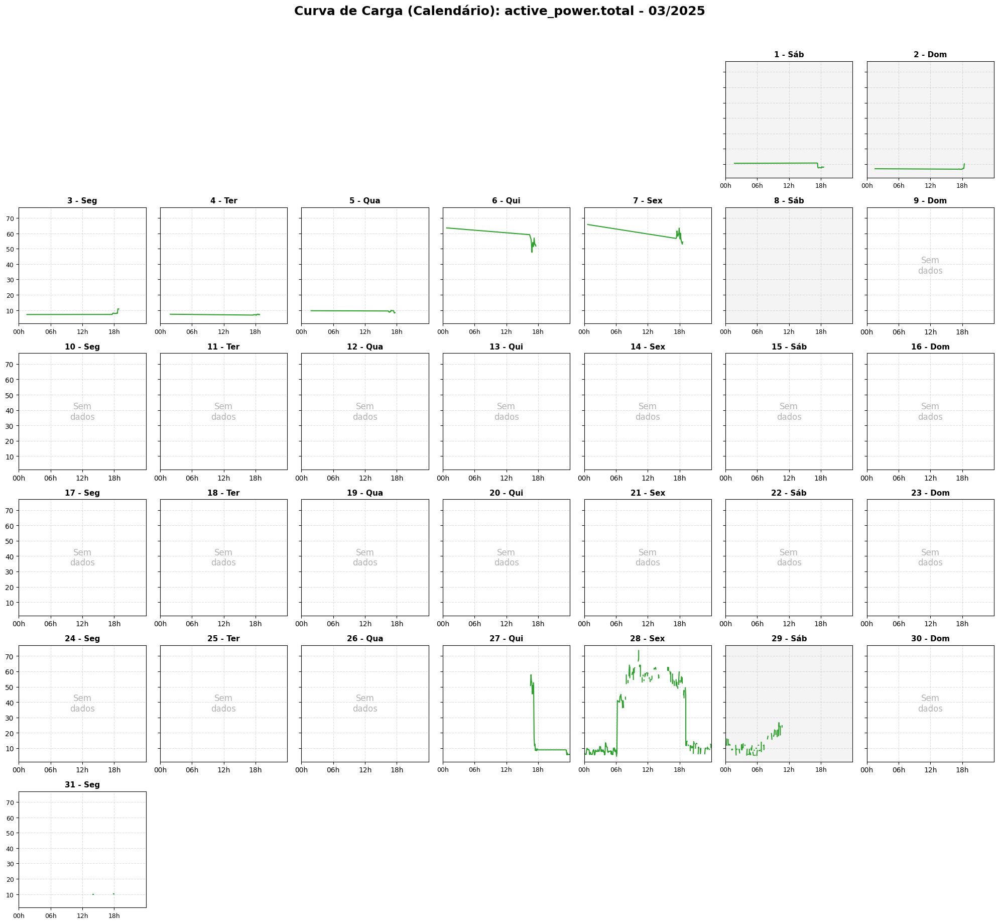

Gerando gráfico: Medidor_PF | 06/2025


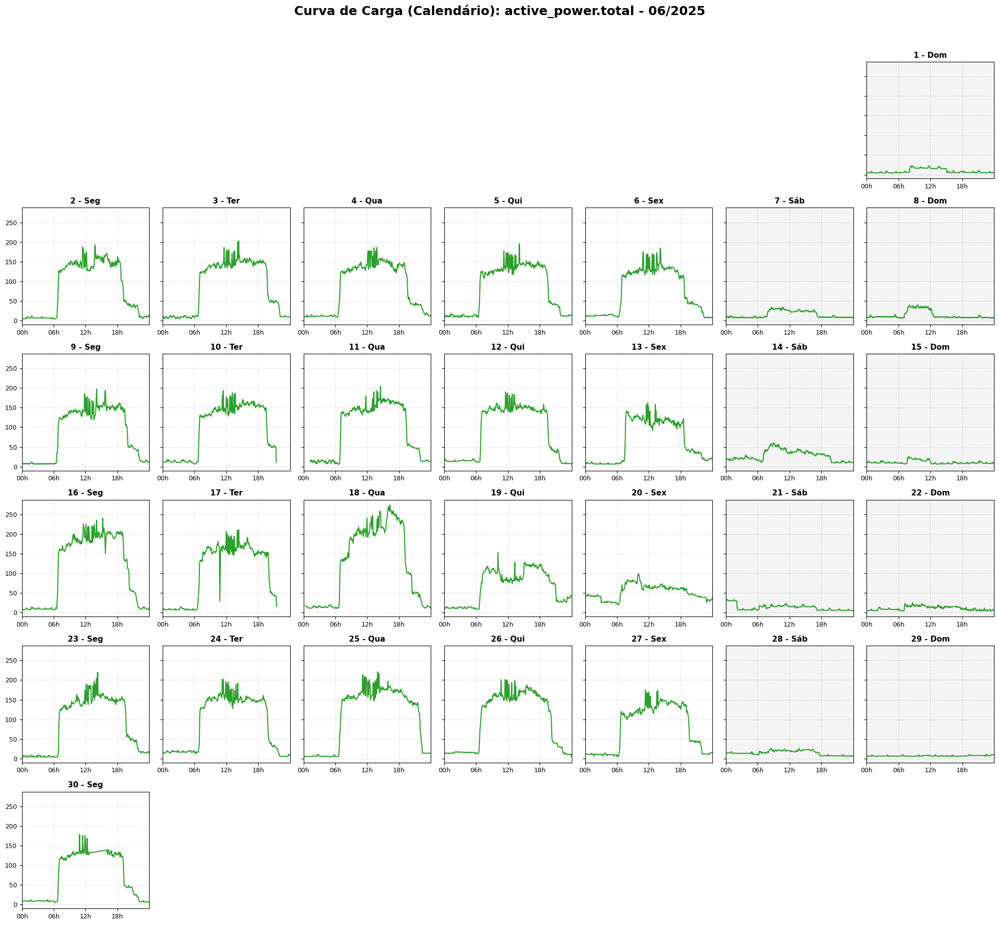

Gerando gráfico: Medidor_PF | 07/2025


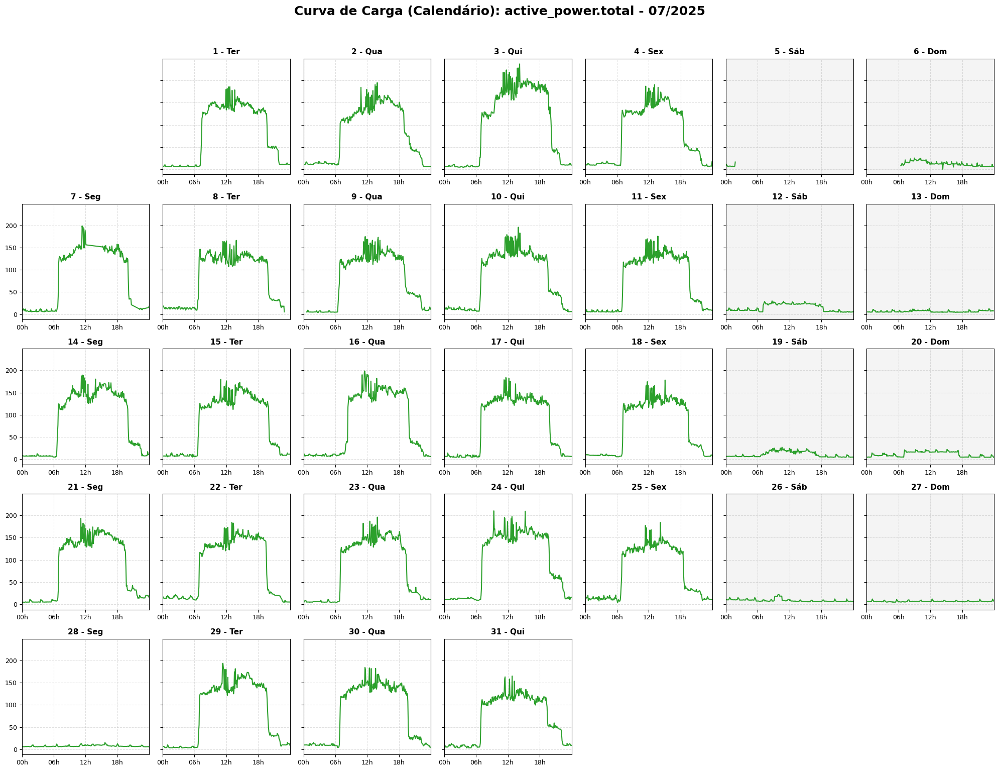

Gerando gráfico: Medidor_PF | 08/2025


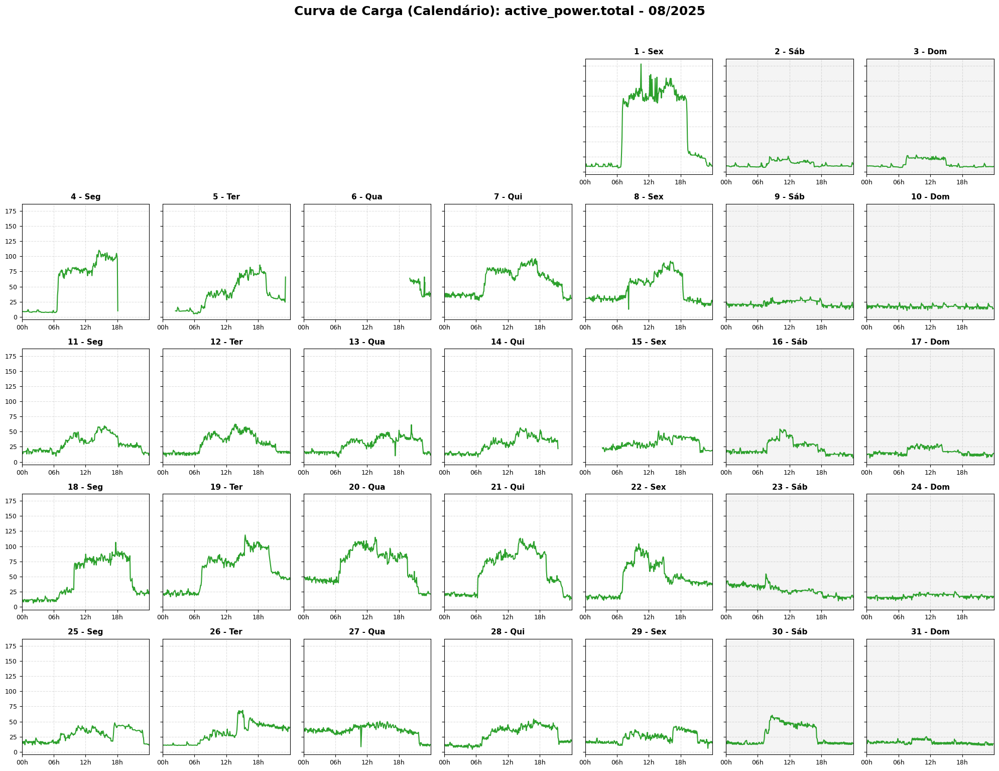

Gerando gráfico: Medidor_PF | 09/2025


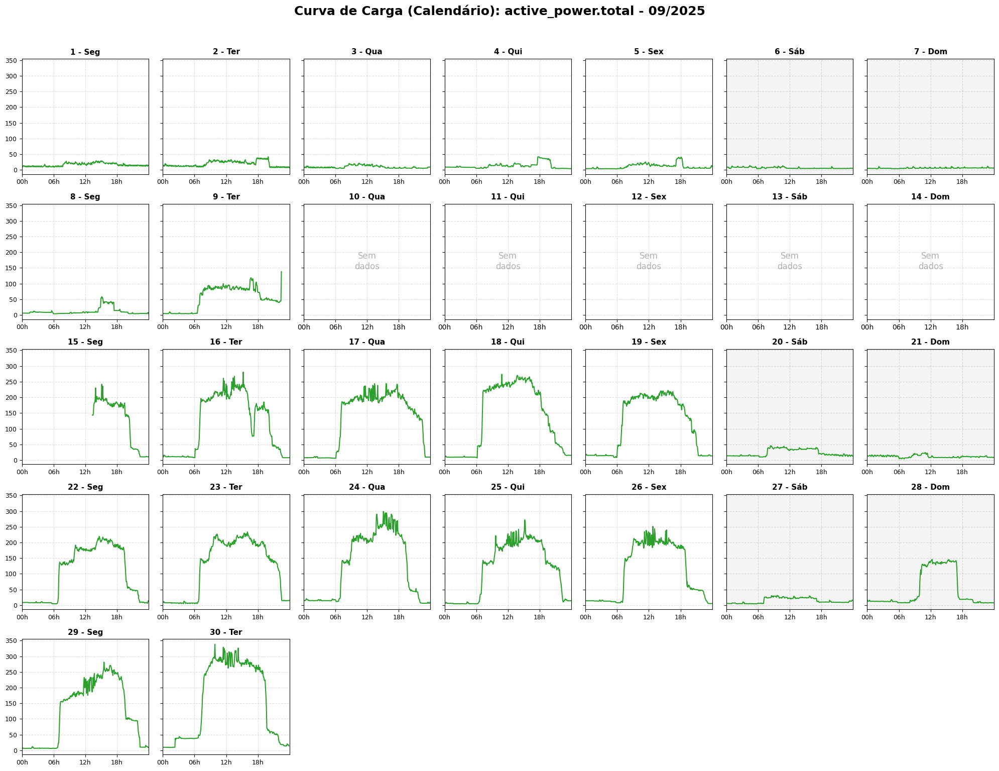

Gerando gráfico: Medidor_PF | 11/2025


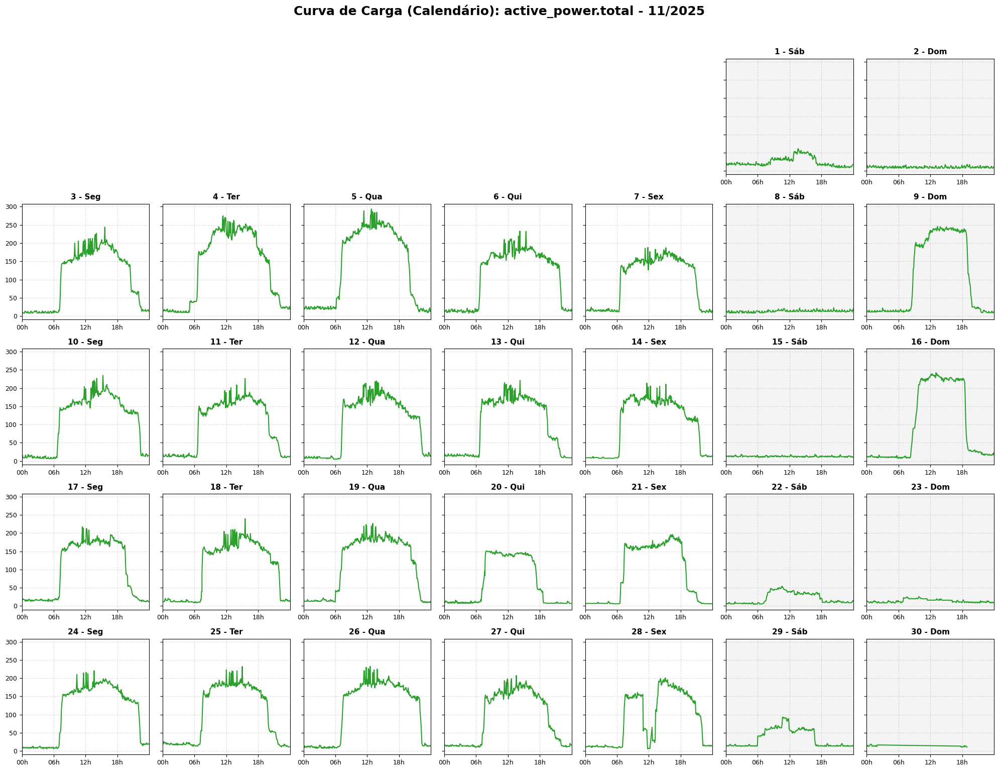

Gerando gráfico: Medidor_PF | 12/2025


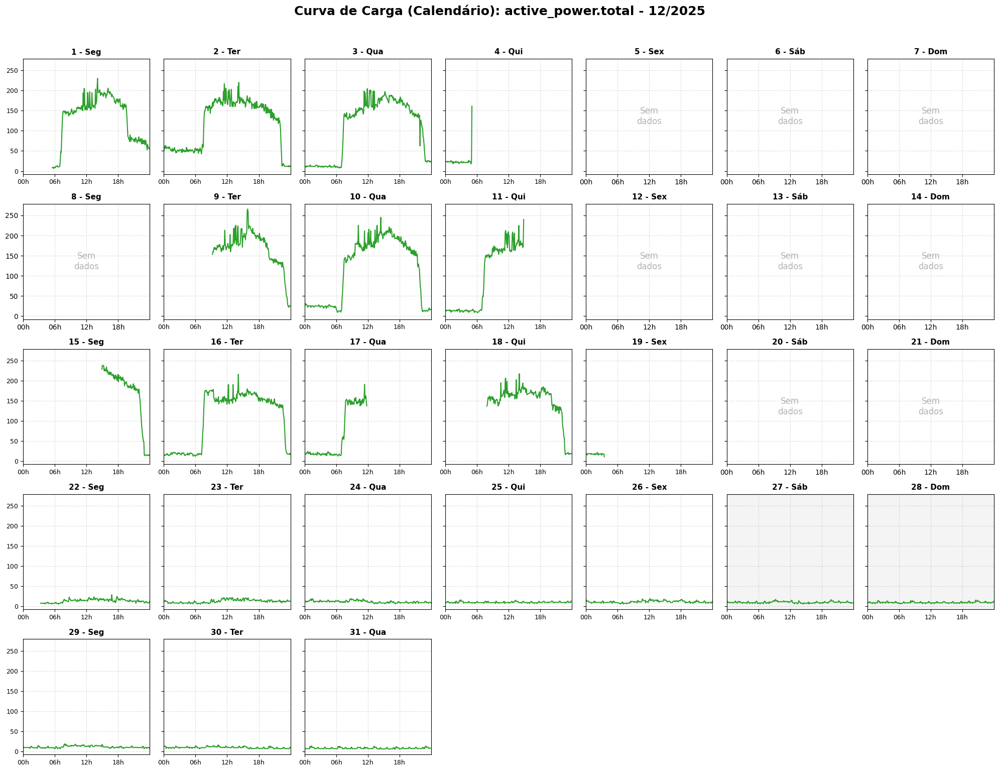

Gerando gráfico: Medidor_PF | 03/2026


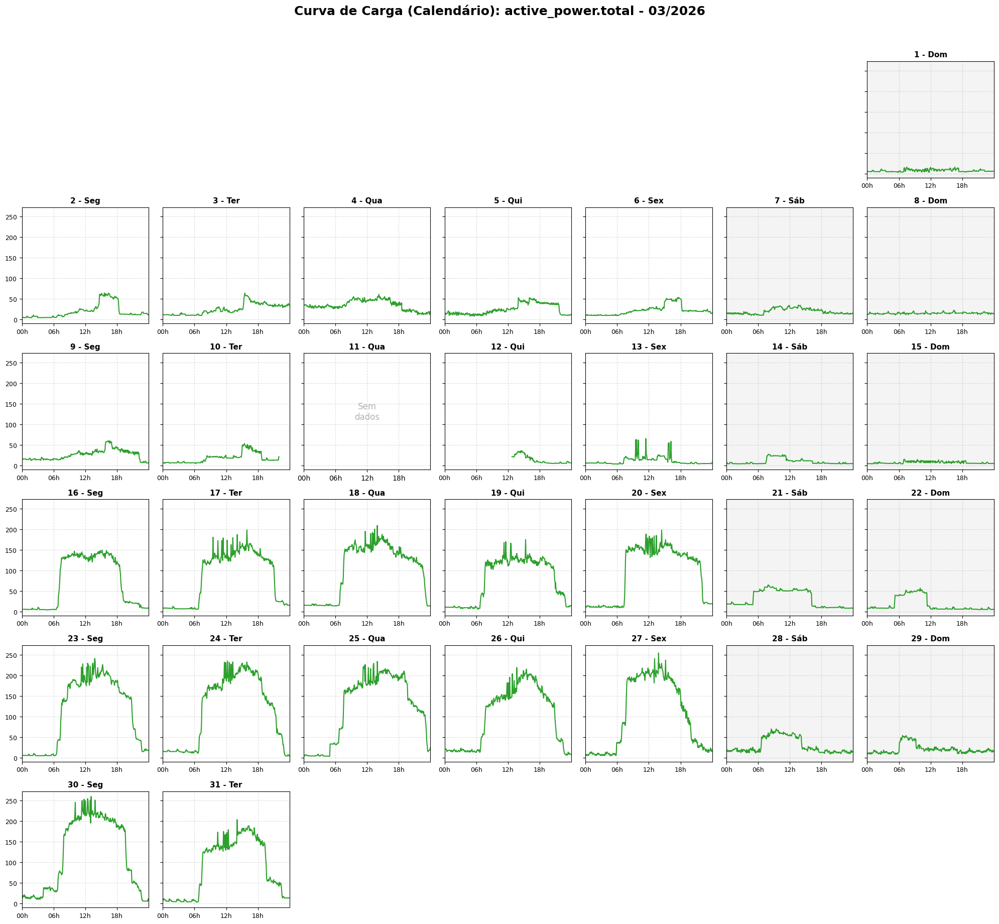

Gerando gráfico: Medidor_PF | 04/2026


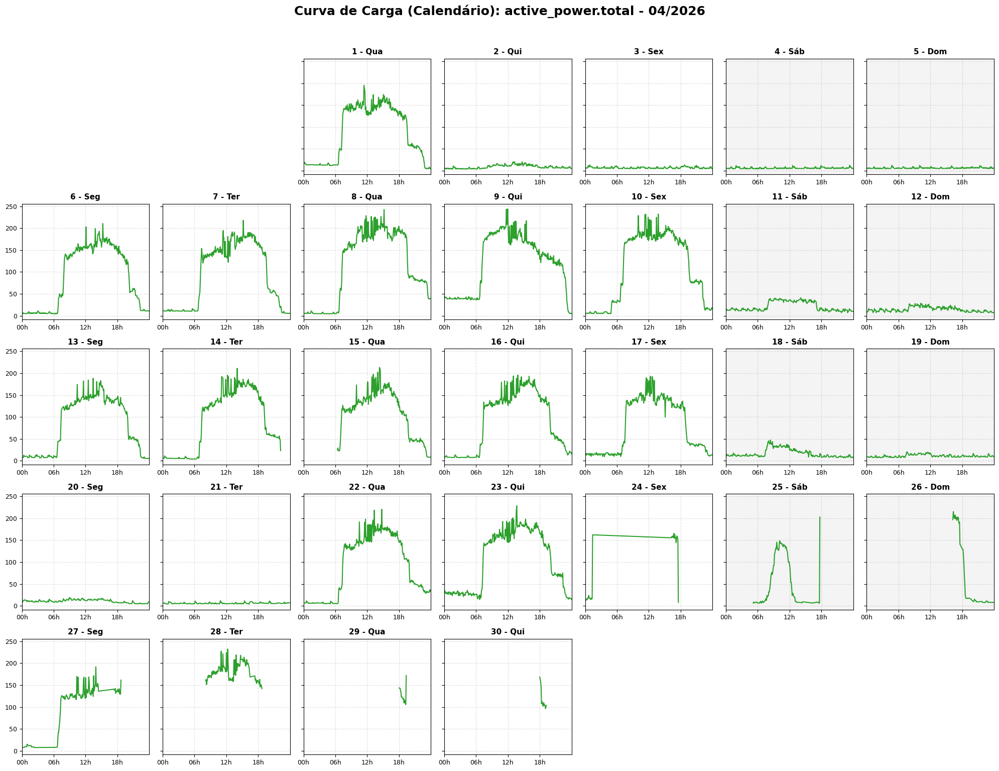

Gerando gráfico: Medidor_PF | 10/2026


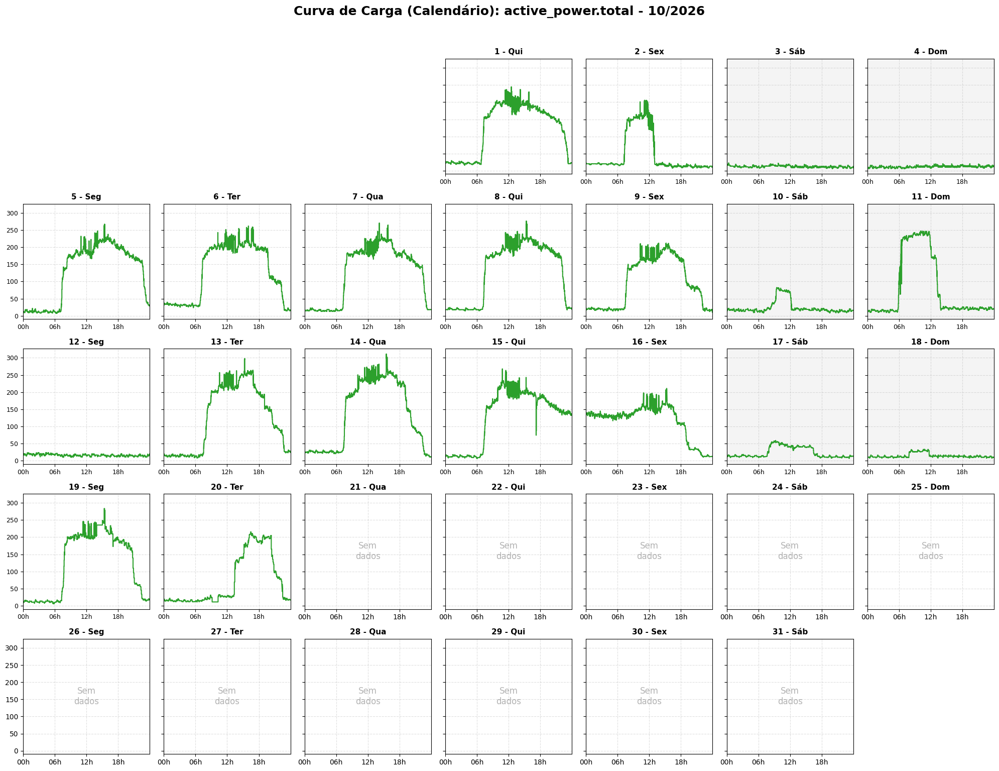

In [8]:
import os
import matplotlib.pyplot as plt
import pandas as pd


def main():
    pasta_destino = "graficos_mensais_para cada"
    os.makedirs(pasta_destino, exist_ok=True)

    for item_caminho in caminho:
        nome_medidor = os.path.basename(item_caminho).replace(".csv", "")
        print(f"\n--- Processando: {nome_medidor} ---")

        df = pd.read_csv(item_caminho, low_memory=False)

        df = calcular_potencia_ativa_total(df)
        df = preparar_dados_temporais(
            df, coluna_tempo="timestamp_leitura_anterior"
        )

        for ano in [2025, 2026]:
            for mes in range(1, 13):
                if hasattr(df.index, "year"):
                    dados_mes = df[
                        (df.index.year == ano) & (df.index.month == mes)
                    ]
                    if dados_mes.empty:
                        continue

                print(f"Gerando gráfico: {nome_medidor} | {mes:02d}/{ano}")

                plotar_calendario_mensal(
                    df, ano=ano, mes=mes, coluna="active_power.total"
                )

                nome_arquivo = f"{pasta_destino}/{nome_medidor}{ano}{mes:02d}_calendario.png"
                plt.savefig(nome_arquivo, bbox_inches="tight", dpi=300)

                plt.close()


if __name__ == "__main__":
    main()

In [ ]:
import os
import matplotlib.pyplot as plt
import pandas as pd


def main():
    pasta_destino = "graficos_mensais_para_cada"
    os.makedirs(pasta_destino, exist_ok=True)

    for item_caminho in caminho:
        nome_medidor = os.path.basename(item_caminho).replace(".csv", "")
        print(f"\n--- Processando: {nome_medidor} ---")

        df = pd.read_csv(item_caminho, low_memory=False)

        df = calcular_potencia_ativa_total(df)
        df = preparar_dados_temporais(
            df, coluna_tempo="timestamp_leitura_anterior"
        )

        for ano in [2025, 2026]:
            for mes in range(1, 13):
                if hasattr(df.index, "year"):
                    dados_mes = df[
                        (df.index.year == ano) & (df.index.month == mes)
                    ]
                    if dados_mes.empty:
                        continue

                print(f"Gerando gráfico: {nome_medidor} | {mes:02d}/{ano}")

                # 1. Retorna o objeto fig
                fig = plotar_calendario_mensal(
                    df, ano=ano, mes=mes, coluna="active_power.total"
                )

                if fig is not None:
                    # 2. Salva a figura antes de fechar
                    nome_arquivo = f"{pasta_destino}/{nome_medidor}{ano}{mes:02d}_calendario.png"
                    fig.savefig(nome_arquivo, bbox_inches="tight", dpi=300)

                    # 3. Exibe no notebook se desejado (opcional)
                    # plt.show()

                    # 4. Libera a memória da figura
                    plt.close(fig)


if __name__ == "__main__":
    main()


--- Processando: Medidor_BIO ---
⚡ Coluna 'active_power.total' calculada e adicionada com sucesso!
✅ Dados temporais tratados. Coluna 'dia_da_semana' adicionada e índice configurado.
Gerando gráfico: Medidor_BIO | 12/2025
Gerando gráfico: Medidor_BIO | 03/2026


In [9]:
import os
import gc  # Módulo nativo do Python para forçar a limpeza de memória RAM
import matplotlib
# ESTRATÉGIA 1: Força o Matplotlib a rodar em modo "Background" (Agg). 
# Isso impede que ele tente renderizar as telas no WSL, economizando muita CPU e RAM.
matplotlib.use('Agg') 
import matplotlib.pyplot as plt
import pandas as pd

# Importe suas funções aqui (calcular_potencia_ativa_total, preparar_dados_temporais, plotar_calendario_mensal)

def main():
    pasta_destino = "graficos_mensais_para_cada"
    os.makedirs(pasta_destino, exist_ok=True)

    # Recomendo que 'caminho' seja definido ou passado como argumento
    for item_caminho in caminho:
        nome_medidor = os.path.basename(item_caminho).replace(".csv", "")
        print(f"\n--- Processando Prédio: {nome_medidor} ---")

        # Lê os dados do prédio atual
        df = pd.read_csv(item_caminho, low_memory=False)

        # Feature Engineering e Tratamento
        df = calcular_potencia_ativa_total(df)
        df = preparar_dados_temporais(df, coluna_tempo="timestamp_leitura_anterior")

        for ano in [2025, 2026]:
            for mes in range(1, 13):
                if hasattr(df.index, "year"):
                    dados_mes = df[
                        (df.index.year == ano) & (df.index.month == mes)
                    ]
                    
                    if dados_mes.empty:
                        continue

                    print(f"  -> Gerando gráfico: {mes:02d}/{ano}")

                    fig = plotar_calendario_mensal(
                        df, ano=ano, mes=mes, coluna="active_power.total"
                    )

                    if fig is not None:
                        # Evita sobrescrever arquivos arrumando o nome
                        nome_arquivo = f"{pasta_destino}/{nome_medidor}_{ano}_{mes:02d}_calendario.png"
                        
                        # ESTRATÉGIA 2: dpi=150. Como os gráficos do calendário já são enormes (figsize 20x15), 
                        # 150 dpi já garante alta definição sem explodir a sua memória RAM na exportação.
                        fig.savefig(nome_arquivo, bbox_inches="tight", dpi=150)

                        # ESTRATÉGIA 3: Destruição agressiva da figura na RAM
                        fig.clf()           # Limpa todos os eixos (limpa a matriz de pixels)
                        plt.close(fig)      # Fecha a figura específica
                        del fig             # Deleta a variável do ambiente Python
                        plt.close('all')    # Garante que nenhum processo gráfico ficou aberto em background

        # ESTRATÉGIA 4: Limpeza do Prédio
        # Ao terminar os anos/meses de um prédio, excluímos o DataFrame gigantesco
        # antes de carregar o CSV do próximo prédio no topo do loop.
        del df
        gc.collect() # Invoca o Garbage Collector para esvaziar a RAM do computador instantaneamente
        
        print(f"✅ Prédio {nome_medidor} finalizado. Memória RAM liberada para o próximo.")

if __name__ == "__main__":
    main()


--- Processando Prédio: Medidor_CCET ---
⚡ Coluna 'active_power.total' calculada e adicionada com sucesso!
✅ Dados temporais tratados. Coluna 'dia_da_semana' adicionada e índice configurado.
  -> Gerando gráfico: 01/2025
  -> Gerando gráfico: 03/2025
  -> Gerando gráfico: 06/2025
  -> Gerando gráfico: 07/2025
  -> Gerando gráfico: 08/2025
  -> Gerando gráfico: 09/2025
  -> Gerando gráfico: 11/2025
  -> Gerando gráfico: 12/2025
  -> Gerando gráfico: 03/2026
  -> Gerando gráfico: 04/2026
  -> Gerando gráfico: 10/2026
✅ Prédio Medidor_CCET finalizado. Memória RAM liberada para o próximo.

--- Processando Prédio: Medidor_BIO ---
⚡ Coluna 'active_power.total' calculada e adicionada com sucesso!
✅ Dados temporais tratados. Coluna 'dia_da_semana' adicionada e índice configurado.
  -> Gerando gráfico: 12/2025
  -> Gerando gráfico: 03/2026
  -> Gerando gráfico: 04/2026
  -> Gerando gráfico: 10/2026
✅ Prédio Medidor_BIO finalizado. Memória RAM liberada para o próximo.

--- Processando Prédio: M

/home/ls/TCC_2026/Dados greefra/mes_1/EDA_Funcions/eda_graficos.py:117: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()


  -> Gerando gráfico: 08/2025
  -> Gerando gráfico: 09/2025
  -> Gerando gráfico: 11/2025
  -> Gerando gráfico: 12/2025
  -> Gerando gráfico: 03/2026
  -> Gerando gráfico: 04/2026
  -> Gerando gráfico: 10/2026
✅ Prédio Medidor_CCH finalizado. Memória RAM liberada para o próximo.

--- Processando Prédio: Medidor_CCSO ---
⚡ Coluna 'active_power.total' calculada e adicionada com sucesso!
✅ Dados temporais tratados. Coluna 'dia_da_semana' adicionada e índice configurado.
  -> Gerando gráfico: 07/2025
  -> Gerando gráfico: 08/2025
  -> Gerando gráfico: 09/2025
  -> Gerando gráfico: 11/2025
  -> Gerando gráfico: 12/2025
  -> Gerando gráfico: 03/2026
  -> Gerando gráfico: 10/2026
✅ Prédio Medidor_CCSO finalizado. Memória RAM liberada para o próximo.

--- Processando Prédio: Medidor_IEE ---
⚡ Coluna 'active_power.total' calculada e adicionada com sucesso!
✅ Dados temporais tratados. Coluna 'dia_da_semana' adicionada e índice configurado.
  -> Gerando gráfico: 01/2025
  -> Gerando gráfico: 03/2